In [1]:
!pip install mne

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 26.2 MB/s eta 0:00:00


In [2]:
#Import necessary Librry
import os
import time
import numpy as np
import pandas as pd

import numpy as np
from tqdm.notebook import tqdm

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.metrics import confusion_matrix, f1_score, classification_report, accuracy_score
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
import joblib

import mne

import keras
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense
from keras.regularizers import l2
from keras import backend as K
from tensorflow.keras.layers import Conv1D, MaxPooling1D, GlobalMaxPooling1D, Dropout,\
 Flatten, Dense, Reshape, LSTM,  SimpleRNN, GRU, Bidirectional, Activation

from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dropout, Flatten,\
 BatchNormalization,  DepthwiseConv2D, AveragePooling2D, SeparableConv2D

from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models, Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import load_model
#from wandb.integration.keras import WandbCallback
import warnings
warnings.filterwarnings('ignore')

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
for dirname, _, filenames in os.walk('/content/drive/MyDrive/EEG_80'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/content/drive/MyDrive/EEG_80/1.csv
/content/drive/MyDrive/EEG_80/10.csv
/content/drive/MyDrive/EEG_80/11.csv
/content/drive/MyDrive/EEG_80/12.csv
/content/drive/MyDrive/EEG_80/13.csv
/content/drive/MyDrive/EEG_80/14.csv
/content/drive/MyDrive/EEG_80/15.csv
/content/drive/MyDrive/EEG_80/16.csv
/content/drive/MyDrive/EEG_80/17.csv
/content/drive/MyDrive/EEG_80/18.csv
/content/drive/MyDrive/EEG_80/19.csv
/content/drive/MyDrive/EEG_80/2.csv
/content/drive/MyDrive/EEG_80/20.csv
/content/drive/MyDrive/EEG_80/21.csv
/content/drive/MyDrive/EEG_80/22.csv
/content/drive/MyDrive/EEG_80/23.csv
/content/drive/MyDrive/EEG_80/24.csv
/content/drive/MyDrive/EEG_80/3.csv
/content/drive/MyDrive/EEG_80/4.csv
/content/drive/MyDrive/EEG_80/5.csv
/content/drive/MyDrive/EEG_80/6.csv
/content/drive/MyDrive/EEG_80/66.csv
/content/drive/MyDrive/EEG_80/67.csv
/content/drive/MyDrive/EEG_80/68.csv
/content/drive/MyDrive/EEG_80/69.csv
/content/drive/MyDrive/EEG_80/7.csv
/content/drive/MyDrive/EEG_80/70.csv
/content

In [5]:
column_list = pd.read_csv("/content/drive/MyDrive/EEG_80/columnLabels.csv").columns
electrode = pd.read_csv("/content/drive/MyDrive/EEG_80/columnLabels.csv").columns[4:]

In [6]:
column_list

Index(['subject', 'trial', 'condition', 'sample', 'Fp1', 'AF7', 'AF3', 'F1',
       'F3', 'F5', 'F7', 'FT7', 'FC5', 'FC3', 'FC1', 'C1', 'C3', 'C5', 'T7',
       'TP7', 'CP5', 'CP3', 'CP1', 'P1', 'P3', 'P5', 'P7', 'P9', 'PO7', 'PO3',
       'O1', 'Iz', 'Oz', 'POz', 'Pz', 'CPz', 'Fpz', 'Fp2', 'AF8', 'AF4', 'AFz',
       'Fz', 'F2', 'F4', 'F6', 'F8', 'FT8', 'FC6', 'FC4', 'FC2', 'FCz', 'Cz',
       'C2', 'C4', 'C6', 'T8', 'TP8', 'CP6', 'CP4', 'CP2', 'P2', 'P4', 'P6',
       'P8', 'P10', 'PO8', 'PO4', 'O2', 'VEOa', 'VEOb', 'HEOL', 'HEOR', 'Nose',
       'TP10'],
      dtype='object')

In [7]:
demographic = pd.read_csv("/content/drive/MyDrive/EEG_80/demographic.csv")

In [8]:
for i, t in enumerate(list(demographic[" group"])):
  demographic["Patient"] = np.where(demographic[" group"] == 0, "Healthy","Schizoprnia")
  demographic["Patient"] = np.where(demographic[" group"] == 1, "Schizoprnia", "Helathy")

In [9]:
demographic

,subject,group,gender,age,education,Patient
0,1,0,M,44,16.0,Helathy
1,2,0,M,39,17.0,Helathy
2,3,0,M,53,18.0,Helathy
3,4,0,M,52,15.0,Helathy
4,5,0,M,41,16.0,Helathy
...,...,...,...,...,...,...
76,77,1,M,28,13.0,Schizoprnia
77,78,1,F,32,16.0,Schizoprnia
78,79,1,M,37,16.0,Schizoprnia
79,80,1,M,33,13.0,Schizoprnia


In [10]:
count = demographic.groupby(["Patient"], as_index = False)["subject"].count()
count

,Patient,subject
0,Helathy,32
1,Schizoprnia,49


In [11]:
# dict for data preprocessing
dict_ = dict(zip(demographic["subject"], demographic[" group"]))

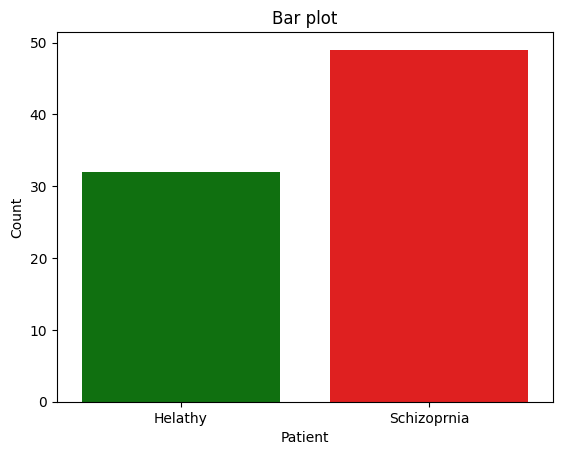

In [ ]:
sns.barplot(x = "Patient", y = "subject", data = count, palette = ["green", "red"])
plt.ylabel("Count")
plt.title("Bar plot")
plt.show()

In [ ]:
time = pd.read_csv("/content/drive/MyDrive/EEG_80/time.csv")
time.head()

,sample,time_ms
0,1,-1500.0000
1,2,-1499.0234
2,3,-1498.0469
3,4,-1497.0703
4,5,-1496.0938


## Schizoprenic and Healthy

In [ ]:
csv_10 = pd.read_csv("/content/drive/MyDrive/EEG_80/10.csv", header=None, names=column_list)
csv_10.head()

,subject,trial,condition,sample,Fp1,AF7,AF3,F1,F3,F5,...,P10,PO8,PO4,O2,VEOa,VEOb,HEOL,HEOR,Nose,TP10
0,10.0,100.0,1.0,1.0,-22.8774,-78.6755,-8.0013,-12.4386,-23.6352,-31.3560,...,43.4493,3.1654,-9.1876,-12.9141,43.3718,-20.7366,5.3274,-28.0435,0.2110,18.6603
1,10.0,100.0,1.0,2.0,-20.1172,-75.1138,-5.9297,-11.1830,-22.1853,-32.4027,...,46.7718,6.1241,-7.2565,-10.6454,43.5867,-17.1981,3.8222,-29.4389,3.7093,17.4339
2,10.0,100.0,1.0,3.0,-20.2351,-75.2874,-5.5513,-9.8152,-20.5348,-32.0249,...,48.5472,4.2711,-8.6834,-10.7720,44.6609,-16.5503,2.3639,-30.5062,2.3482,16.2232
3,10.0,100.0,1.0,4.0,-22.7280,-79.1659,-6.9681,-10.3275,-20.4670,-31.7483,...,50.6465,4.0239,-9.5835,-10.9540,42.1414,-25.9337,-1.4694,-31.8234,-0.5128,15.6688
4,10.0,100.0,1.0,5.0,-27.0743,-84.2088,-10.9203,-13.9038,-23.2044,-33.9135,...,53.4349,3.7302,-11.2227,-12.3021,39.6062,-31.6765,-3.4746,-33.7189,-6.0457,14.3174


In [ ]:
csv_37 = pd.read_csv("/content/drive/MyDrive/EEG_80/37.csv", header=None, names=column_list)
csv_37.head()

,subject,trial,condition,sample,Fp1,AF7,AF3,F1,F3,F5,...,P10,PO8,PO4,O2,VEOa,VEOb,HEOL,HEOR,Nose,TP10
0,37.0,100.0,1.0,1.0,1.1681,37.4027,-40.6399,-27.4674,-60.8957,-94.6145,...,46.1222,-4.1993,-110.4118,37.1749,83.1480,-19.4276,66.5672,46.1873,2.5932,96.7349
1,37.0,100.0,1.0,2.0,-1.6434,34.9030,-43.2394,-29.7139,-63.3286,-96.7482,...,45.8155,-6.9276,-112.7922,34.9177,77.3229,-15.9337,74.6886,46.7635,3.4713,103.1887
2,37.0,100.0,1.0,3.0,-2.9714,32.3400,-43.6542,-31.6725,-64.7148,-97.2714,...,42.9153,-7.1382,-112.8195,34.4698,64.4041,-13.9710,79.4663,49.9959,5.7244,105.5799
3,37.0,100.0,1.0,4.0,-3.0366,30.6723,-42.6233,-31.1452,-64.2292,-96.8728,...,40.4598,-5.9076,-111.2138,35.4907,53.7041,-11.7584,80.2126,55.4470,8.3212,100.1587
4,37.0,100.0,1.0,5.0,-5.1264,28.1461,-44.0419,-32.3592,-66.0499,-99.2053,...,39.7443,-6.0253,-111.1703,35.9560,55.2384,-9.4989,78.7872,59.9451,14.3712,94.4719


## Both dataset demographic details

In [ ]:
demographic[ demographic["subject"] == 10]  #healthy

,subject,group,gender,age,education,Patient
9,10,0,M,53,19.0,Helathy


In [ ]:
demographic[ demographic["subject"] == 37] #Schizoprenia

,subject,group,gender,age,education,Patient
36,37,1,M,53,13.0,Schizoprnia


## Check Non Value

In [ ]:
csv_10.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 903168 entries, 0 to 903167
Data columns (total 74 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   subject    903168 non-null  float64
 1   trial      903168 non-null  float64
 2   condition  903168 non-null  float64
 3   sample     903168 non-null  float64
 4   Fp1        903168 non-null  float64
 5   AF7        903168 non-null  float64
 6   AF3        903168 non-null  float64
 7   F1         903168 non-null  float64
 8   F3         903168 non-null  float64
 9   F5         903168 non-null  float64
 10  F7         903168 non-null  float64
 11  FT7        903168 non-null  float64
 12  FC5        903168 non-null  float64
 13  FC3        903168 non-null  float64
 14  FC1        903168 non-null  float64
 15  C1         903168 non-null  float64
 16  C3         903168 non-null  float64
 17  C5         903168 non-null  float64
 18  T7         903168 non-null  float64
 19  TP7        903168 non-n

In [ ]:
csv_37.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 890880 entries, 0 to 890879
Data columns (total 74 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   subject    890880 non-null  float64
 1   trial      890880 non-null  float64
 2   condition  890880 non-null  float64
 3   sample     890880 non-null  float64
 4   Fp1        890880 non-null  float64
 5   AF7        890880 non-null  float64
 6   AF3        890880 non-null  float64
 7   F1         890880 non-null  float64
 8   F3         890880 non-null  float64
 9   F5         890880 non-null  float64
 10  F7         890880 non-null  float64
 11  FT7        890880 non-null  float64
 12  FC5        890880 non-null  float64
 13  FC3        890880 non-null  float64
 14  FC1        890880 non-null  float64
 15  C1         890880 non-null  float64
 16  C3         890880 non-null  float64
 17  C5         890880 non-null  float64
 18  T7         890880 non-null  float64
 19  TP7        890880 non-n

## Shape of those datset

In [ ]:
csv_10.shape

(903168, 74)

In [ ]:
csv_37.shape

(890880, 74)

## See descriptive statistics

In [ ]:
csv_10.describe() #Healthy

,subject,trial,condition,sample,Fp1,AF7,AF3,F1,F3,F5,...,P10,PO8,PO4,O2,VEOa,VEOb,HEOL,HEOR,Nose,TP10
count,903168.0,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,...,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000
mean,10.0,50.670068,2.003401,1536.500000,3.038784,2.557580,2.768087,2.365992,1.531788,1.328728,...,1.056763,1.308568,1.324111,0.822417,28.577227,-5.780616,3.094929,9.576918,-1.961261,3.589513
std,0.0,28.548280,0.822715,886.810457,51.237065,52.752413,53.271078,50.980171,42.255198,47.982284,...,39.233368,25.086144,18.546366,22.883909,163.010620,78.956308,73.902817,52.269255,77.084253,26.259103
min,10.0,1.000000,1.000000,1.000000,-424.300900,-528.644300,-484.951500,-520.677300,-407.763500,-458.679400,...,-505.043200,-231.782000,-113.497400,-145.660500,-988.492600,-618.715100,-473.197200,-292.353600,-831.549300,-132.883700
25%,10.0,26.000000,1.000000,768.750000,-18.276325,-18.155525,-17.692400,-15.564100,-13.837525,-13.963000,...,-10.454800,-9.358200,-8.647825,-10.181425,-22.246700,-27.629350,-17.388125,-10.972725,-16.228025,-10.034125
50%,10.0,51.000000,2.000000,1536.500000,2.821200,2.172150,2.844850,2.256700,1.664150,1.335250,...,0.843900,0.739750,1.175350,0.469550,5.372000,-1.898600,2.053800,3.678650,-1.298650,2.864900
75%,10.0,75.000000,3.000000,2304.250000,23.954025,22.673600,23.210650,19.844550,17.318125,16.140425,...,11.929300,10.871300,10.968100,10.991125,56.993350,17.806875,24.794100,25.570900,11.648025,16.666925
max,10.0,100.000000,3.000000,3072.000000,444.278700,467.079100,499.295600,537.195800,409.397400,464.443200,...,438.445500,274.736800,126.397300,168.488700,1385.143100,707.793100,558.073100,355.929600,850.171600,221.088000


In [ ]:
csv_37.describe() #Schizoprenia

,subject,trial,condition,sample,Fp1,AF7,AF3,F1,F3,F5,...,P10,PO8,PO4,O2,VEOa,VEOb,HEOL,HEOR,Nose,TP10
count,890880.0,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,...,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000
mean,37.0,50.006897,2.013793,1536.500000,2.589184,2.301261,1.516421,0.486347,1.307449,0.998781,...,0.507303,0.776089,-0.209058,-0.619397,8.287967,-3.649211,0.008991,1.206717,-2.277284,-0.070671
std,0.0,28.733871,0.813560,886.810464,39.063635,32.435068,44.780669,20.820523,47.825575,44.741357,...,26.703878,27.152362,24.732113,28.891287,78.229971,39.449884,26.125861,25.486341,27.276079,44.977510
min,37.0,1.000000,1.000000,1.000000,-399.356800,-449.599500,-333.960100,-211.759200,-380.425000,-280.132800,...,-370.814300,-300.338800,-253.785400,-258.349300,-416.384900,-295.823300,-292.441600,-284.925600,-341.341400,-405.802900
25%,37.0,25.000000,1.000000,768.750000,-11.818725,-9.062725,-14.241875,-8.366050,-13.450125,-13.908800,...,-9.039600,-9.392300,-10.414925,-11.869825,-24.491800,-18.432025,-11.452525,-11.875900,-12.987100,-10.744625
50%,37.0,50.000000,2.000000,1536.500000,1.123650,1.223200,0.706850,0.569850,0.352450,0.399550,...,0.566650,0.792250,0.242200,0.073750,3.620350,-1.222200,0.427800,0.652200,-1.005200,-0.070800
75%,37.0,75.000000,3.000000,2304.250000,15.244850,12.625125,15.945775,9.846900,14.536250,14.742200,...,10.299125,11.634400,10.819025,11.745825,34.956450,12.985900,12.253725,13.858850,9.809325,10.919725
max,37.0,100.000000,3.000000,3072.000000,390.349700,414.352800,297.781800,183.117600,474.248400,328.710000,...,220.985900,372.672300,190.791000,237.684000,368.846300,222.078100,310.113600,188.503900,264.465400,1499.107200


## Total trail unique value

In [ ]:
csv_10.trial.nunique() #Healthy

100

In [ ]:
csv_37.trial.nunique() #Schizoprenia

100

## Trail groupby sample count

In [ ]:
count_10 = csv_10.groupby("trial").count()                     #Healthy
print("Total number of trail :" ,count_10.shape[0])
print(count_10.head())

Total number of trail : 100
       subject  condition  sample   Fp1   AF7   AF3    F1    F3    F5    F7  \
trial                                                                         
1.0       9216       9216    9216  9216  9216  9216  9216  9216  9216  9216   
2.0       9216       9216    9216  9216  9216  9216  9216  9216  9216  9216   
3.0       9216       9216    9216  9216  9216  9216  9216  9216  9216  9216   
4.0       9216       9216    9216  9216  9216  9216  9216  9216  9216  9216   
5.0       9216       9216    9216  9216  9216  9216  9216  9216  9216  9216   

       ...   P10   PO8   PO4    O2  VEOa  VEOb  HEOL  HEOR  Nose  TP10  
trial  ...                                                              
1.0    ...  9216  9216  9216  9216  9216  9216  9216  9216  9216  9216  
2.0    ...  9216  9216  9216  9216  9216  9216  9216  9216  9216  9216  
3.0    ...  9216  9216  9216  9216  9216  9216  9216  9216  9216  9216  
4.0    ...  9216  9216  9216  9216  9216  9216  9216 

In [ ]:
count_9216_f0r_10 = count_10[count_10["subject"]== 9216]    #Healthy
print("Total number of train with contain each trail 9216 temporal sample is :", count_9216_f0r_10.shape[0])

Total number of train with contain each trail 9216 temporal sample is : 94


In [ ]:
count_37 = csv_37.groupby("trial").count()                 #Schizoprenia
print("Total number of trail :" ,count_37.shape[0])
print(count_37.head())

Total number of trail : 100
       subject  condition  sample   Fp1   AF7   AF3    F1    F3    F5    F7  \
trial                                                                         
1.0       6144       6144    6144  6144  6144  6144  6144  6144  6144  6144   
2.0       9216       9216    9216  9216  9216  9216  9216  9216  9216  9216   
3.0       9216       9216    9216  9216  9216  9216  9216  9216  9216  9216   
4.0       9216       9216    9216  9216  9216  9216  9216  9216  9216  9216   
5.0       9216       9216    9216  9216  9216  9216  9216  9216  9216  9216   

       ...   P10   PO8   PO4    O2  VEOa  VEOb  HEOL  HEOR  Nose  TP10  
trial  ...                                                              
1.0    ...  6144  6144  6144  6144  6144  6144  6144  6144  6144  6144  
2.0    ...  9216  9216  9216  9216  9216  9216  9216  9216  9216  9216  
3.0    ...  9216  9216  9216  9216  9216  9216  9216  9216  9216  9216  
4.0    ...  9216  9216  9216  9216  9216  9216  9216 

In [ ]:
count_9216_for_37 = count_37[count_37["subject"]== 9216]    #Healthy
print("Total number of train with contain each trail 9216 temporal sample is :", count_9216_for_37.shape[0])

Total number of train with contain each trail 9216 temporal sample is : 90


## Schizoprenia and helathy by Age 53

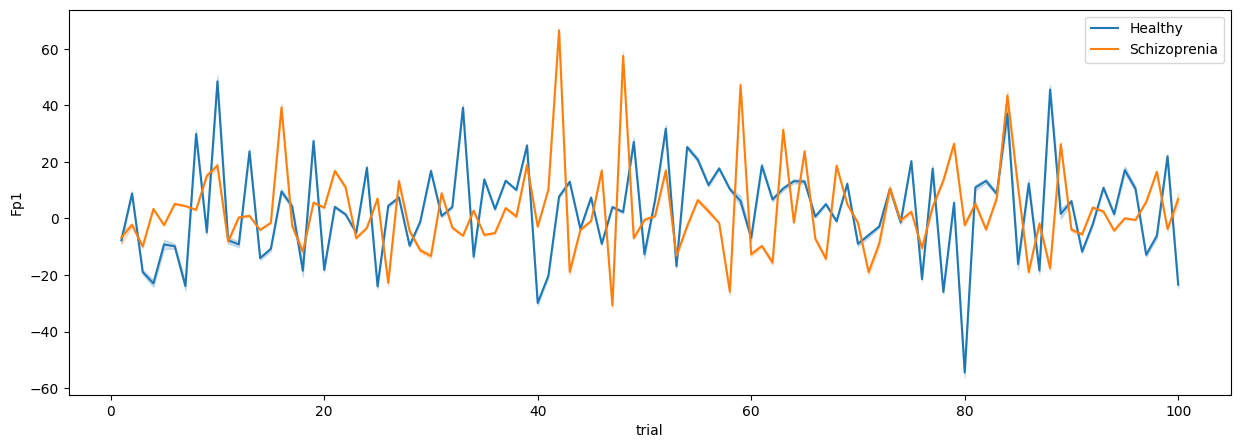

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(15,5))
sns.lineplot(x = "trial", y = "Fp1", data = csv_10, ax = ax, label = "Healthy")
sns.lineplot(x = "trial", y = "Fp1", data = csv_37, ax = ax, label = "Schizoprenia")
plt.legend()
plt.show()

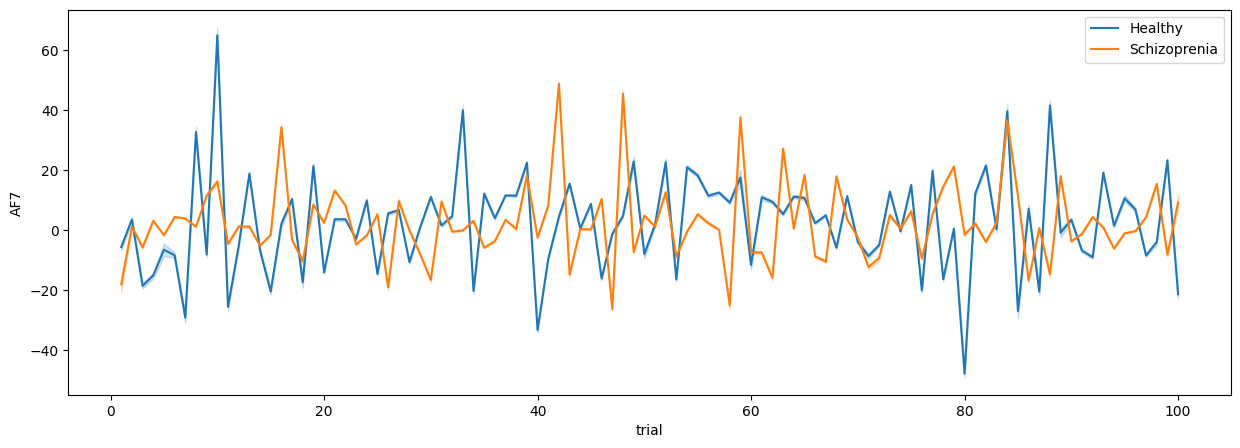

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(15,5))
sns.lineplot(x = "trial", y = "AF7", data = csv_10, ax = ax, label = "Healthy")
sns.lineplot(x = "trial", y = "AF7", data = csv_37, ax = ax, label = "Schizoprenia")
plt.legend()
plt.show()

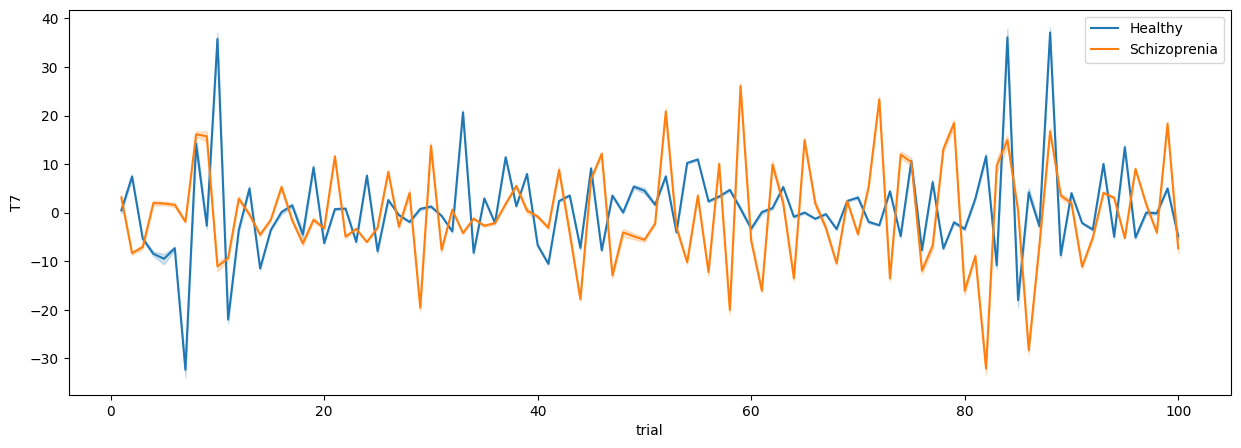

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(15,5))
sns.lineplot(x = "trial", y = "T7", data = csv_10, ax = ax, label = "Healthy")
sns.lineplot(x = "trial", y = "T7", data = csv_37, ax = ax, label = "Schizoprenia")
plt.legend()
plt.show()

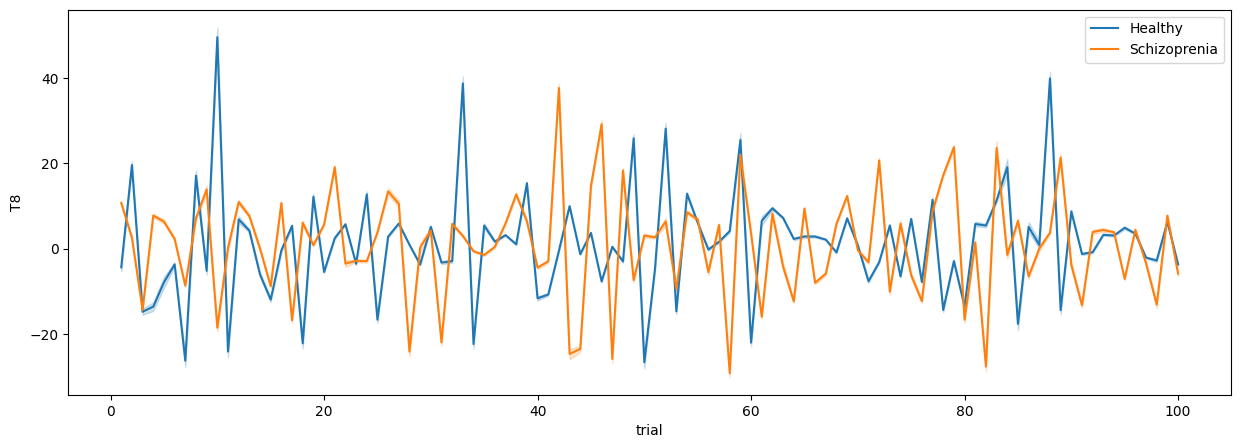

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(15,5))
sns.lineplot(x = "trial", y = "T8", data = csv_10, ax = ax, label = "Healthy")
sns.lineplot(x = "trial", y = "T8", data = csv_37, ax = ax, label = "Schizoprenia")
plt.legend()
plt.show()

## Age 44

In [ ]:
csv_1 = pd.read_csv("/content/drive/MyDrive/EEG_80/1.csv", header=None, names=column_list)
csv_25 = pd.read_csv("/content/drive/MyDrive/EEG_80/25.csv", header=None, names=column_list)

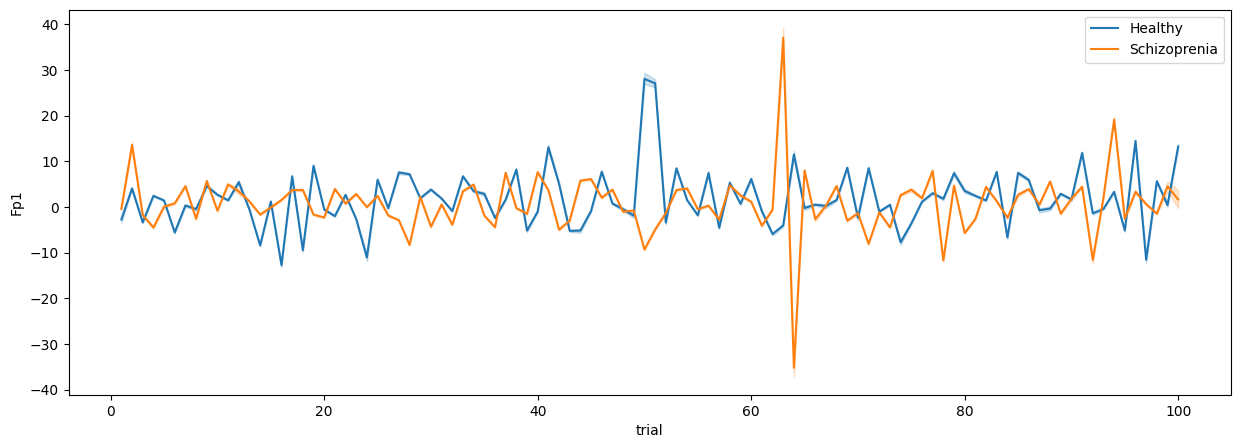

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(15,5))
sns.lineplot(x = "trial", y = "Fp1", data = csv_1, ax = ax, label = "Healthy")
sns.lineplot(x = "trial", y = "Fp1", data = csv_25, ax = ax, label = "Schizoprenia")
plt.legend()
plt.show()

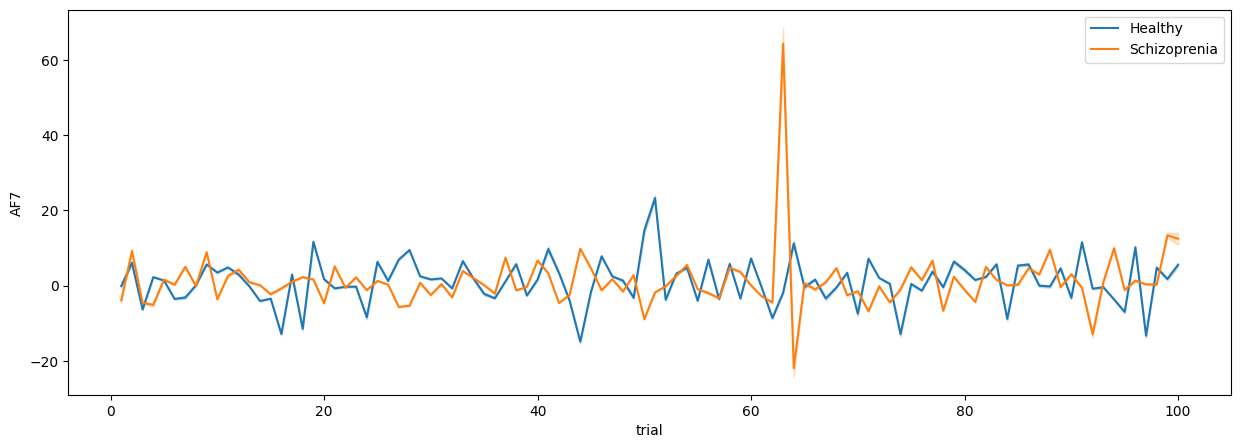

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(15,5))
sns.lineplot(x = "trial", y = "AF7", data = csv_1, ax = ax, label = "Healthy")
sns.lineplot(x = "trial", y = "AF7", data = csv_25, ax = ax, label = "Schizoprenia")
plt.legend()
plt.show()

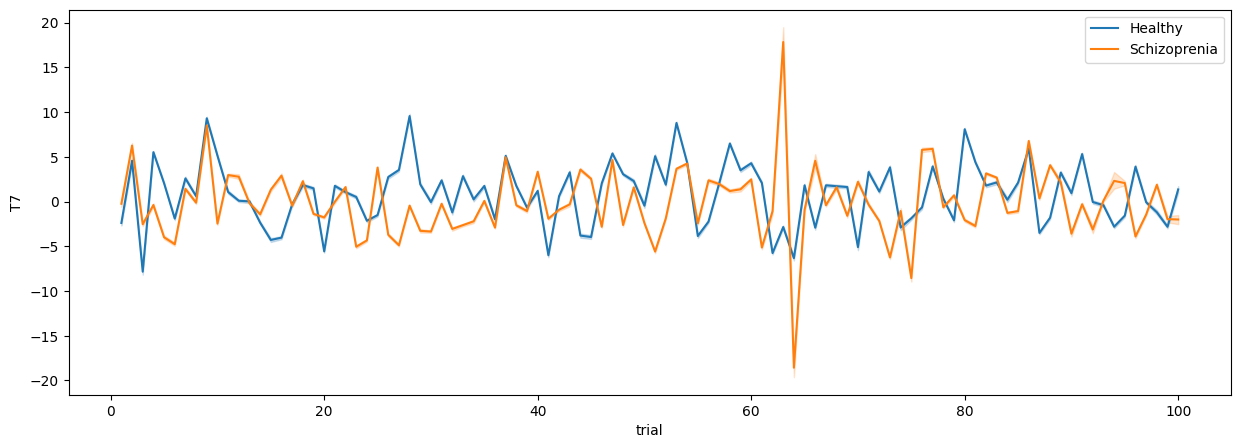

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(15,5))
sns.lineplot(x = "trial", y = "T7", data = csv_1, ax = ax, label = "Healthy")
sns.lineplot(x = "trial", y = "T7", data = csv_25, ax = ax, label = "Schizoprenia")
plt.legend()
plt.show()

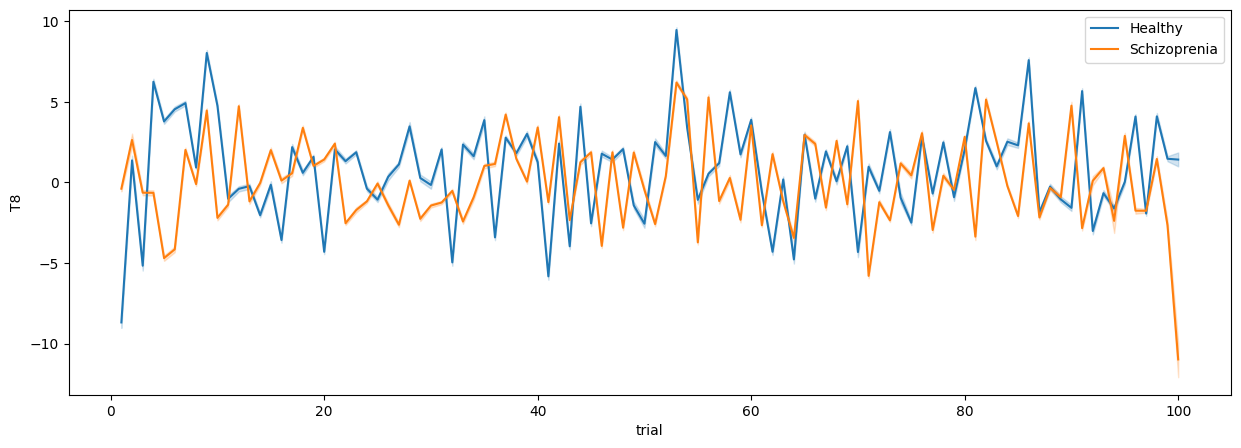

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(15,5))
sns.lineplot(x = "trial", y = "T8", data = csv_1, ax = ax, label = "Healthy")
sns.lineplot(x = "trial", y = "T8", data = csv_25, ax = ax, label = "Schizoprenia")
plt.legend()
plt.show()

## Plot for all electrodes

In [ ]:
csv_10_elec = csv_10.iloc[:, 3:]
csv_37_elec = csv_37.iloc[:, 3:]

In [ ]:
time_csv_10 = csv_10_elec.merge(time, on = 'sample', how = "left")
time_csv_37 = csv_37_elec.merge(time, on = 'sample', how = "left")

In [ ]:
data = time_csv_10.T.values
raw_10 = mne.io.RawArray(data, info = mne.create_info(ch_names = list(time_csv_10.columns), sfreq = 256, ch_types = "eeg"))

Creating RawArray with float64 data, n_channels=72, n_times=903168
    Range : 0 ... 903167 =      0.000 ...  3527.996 secs
Ready.


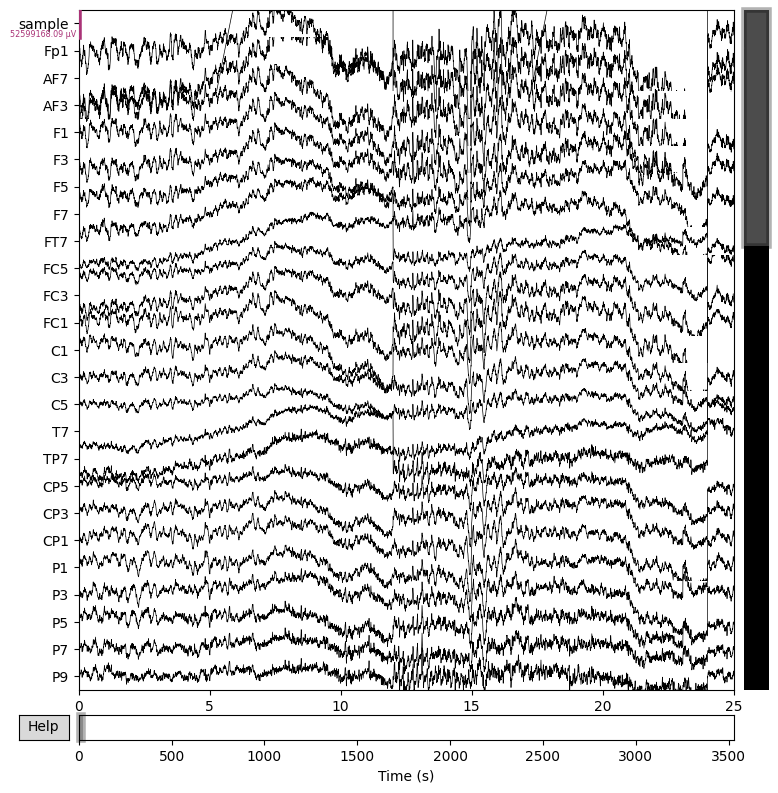

In [ ]:
mne_10 = raw_10.plot(n_channels = 25, duration = 25, scalings = "auto", show = True )
plt.show()
mne_10.savefig("mne_10.jpg")

In [ ]:
data = time_csv_37.T.values
raw_37 = mne.io.RawArray(data, info = mne.create_info(ch_names = list(time_csv_37.columns), sfreq = 256, ch_types = "eeg"))

Creating RawArray with float64 data, n_channels=72, n_times=890880
    Range : 0 ... 890879 =      0.000 ...  3479.996 secs
Ready.


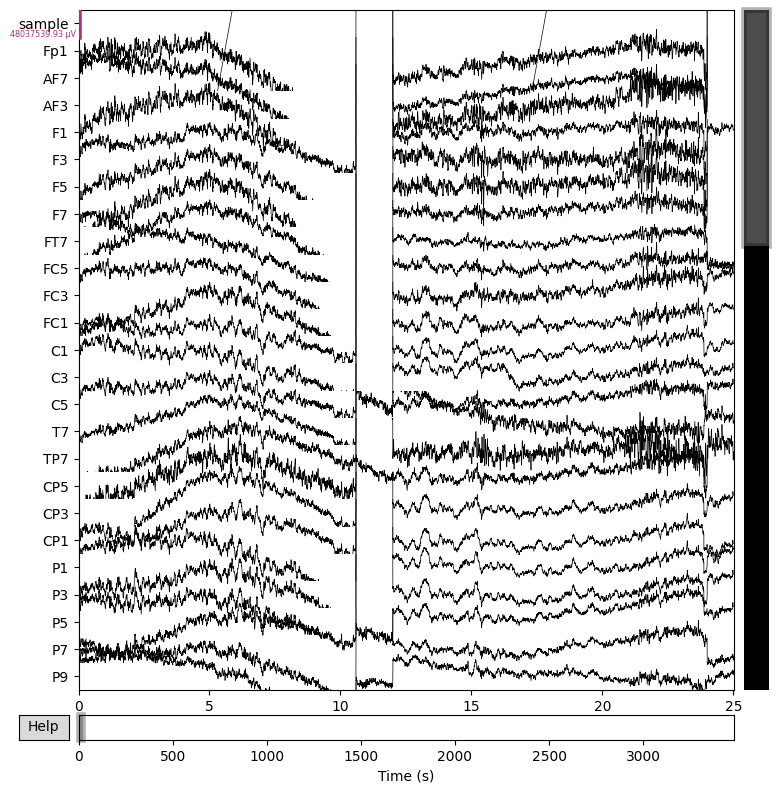

In [ ]:
mne_37 = raw_37.plot(n_channels = 25, duration = 25, scalings = "auto", show = True )
plt.show()
mne_37.savefig("mne_37.jpg")

### Data Processing for model

In [12]:
def average(m, n):
    shape = m.shape
    assert len(shape) == 2
    assert shape[0] % n == 0
    a = m.reshape(shape[0] // n, n,
                  shape[1])
    mean_vector = a.mean(axis=1)
    return mean_vector

In [13]:
n = 16
x_count = 0
X = np.zeros((81 * 100,  9216 * len(electrode) // n), dtype="float32")
Y = np.zeros(len(X))

part1_path = "/content/drive/MyDrive/EEG_80"



column_list = pd.read_csv("/content/drive/MyDrive/EEG_80/columnLabels.csv").columns
for person_num in tqdm(range(1, 82)):


    csv_path = f"{part1_path}/{person_num}.csv"

    df = pd.read_csv(csv_path,
                header=None,
                names=column_list)
    trial_list = set(df.trial)


    for t1, trial_number in enumerate(trial_list):
        trials = len(df[df.trial == trial_number])
        if trials == 9216.0:
            matrix = df[df.trial == trial_number][electrode].values
            averaged = average(matrix, n = n)
            averaged_N = averaged.reshape(-1)
            X[x_count] = averaged_N.astype(np.float32)
            Y[x_count] = dict_[person_num]
            x_count += 1

X = X[: x_count]
Y = Y[: x_count]
print("Total trials for X - ", x_count)
print("Total trials for Y- ", x_count)

  0%|          | 0/81 [00:00<?, ?it/s]

Total trials for X -  7092
Total trials for Y-  7092


In [14]:
#Normalization

X_norm = (normalize(X.reshape(-1, 70), axis=0, norm='max')).reshape(X.shape)
X_norm.shape

(7092, 40320)

In [15]:
#Train test split
X_train, X_test, Y_train, Y_test = train_test_split(X_norm, Y, test_size=0.2, shuffle=True, random_state=42)

### CNN

In [16]:
X_train_1d = X_train.reshape(-1, 576, 70)
X_test_1d = X_test.reshape(-1, 576, 70)

In [ ]:
model1d = Sequential()


model1d.add(Conv1D(filters=64, kernel_size=5, activation='relu', input_shape=(576, 70)))
model1d.add(BatchNormalization())
model1d.add(MaxPooling1D(pool_size=2))
model1d.add(Dropout(0.3))


model1d.add(Conv1D(filters=128, kernel_size=3, activation='relu'))
model1d.add(BatchNormalization())
model1d.add(MaxPooling1D(pool_size=2))
model1d.add(Dropout(0.4))


model1d.add(Conv1D(filters=256, kernel_size=3, activation='relu'))
model1d.add(BatchNormalization())
model1d.add(MaxPooling1D(pool_size=2))
model1d.add(Dropout(0.4))

model1d.add(Flatten())

model1d.add(Dense(128, activation='relu'))
model1d.add(Dropout(0.3))
model1d.add(Dense(1, activation='sigmoid'))

In [ ]:
model1d.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model1d.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 572, 64)             │          22,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 572, 64)             │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 284, 128)            │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 284, 128)            │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_1 (MaxPooling1D)       │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                    │ (None, 140, 256)            │          98,560 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 140, 256)            │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_2 (MaxPooling1D)       │ (None, 70, 256)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 70, 256)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 17920)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       2,293,888 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,441,537 (9.31 MB)

 Trainable params: 2,440,641 (9.31 MB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
history_1d = model1d.fit(X_train_1d, Y_train, epochs= 100, batch_size=16, validation_data=(X_test_1d, Y_test))

Epoch 1/100
355/355 ━━━━━━━━━━━━━━━━━━━━ 18s 42ms/step - accuracy: 0.5865 - loss: 0.9856 - val_accuracy: 0.4137 - val_loss: 5.0027
Epoch 2/100
355/355 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.6839 - loss: 0.6016 - val_accuracy: 0.7202 - val_loss: 1.1730
Epoch 3/100
355/355 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.7208 - loss: 0.5423 - val_accuracy: 0.7160 - val_loss: 0.7901
Epoch 4/100
355/355 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.7826 - loss: 0.4689 - val_accuracy: 0.7569 - val_loss: 0.6821
Epoch 5/100
355/355 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.7972 - loss: 0.4279 - val_accuracy: 0.7773 - val_loss: 0.4910
Epoch 6/100
355/355 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.8278 - loss: 0.3936 - val_accuracy: 0.8140 - val_loss: 0.4212
Epoch 7/100
355/355 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.8589 - loss: 0.3540 - val_accuracy: 0.7766 - val_loss: 0.4927
Epoch 8/100
355/355 ━━━━━━━━━━━━━━━━━━━━ 15s 41ms/step - accuracy: 0.8960 - loss: 0

In [ ]:
model1d.evaluate(X_test_1d, Y_test)

45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9245 - loss: 0.2455


[0.21394523978233337, 0.9323467016220093]

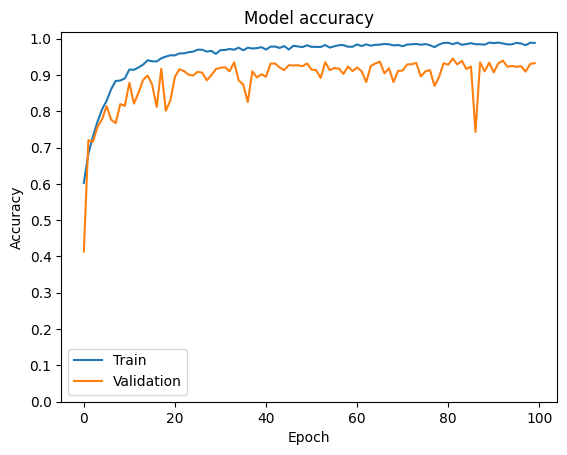

In [ ]:
# Plot training & validation accuracy values
plt.plot(history_1d.history['accuracy'])
plt.plot(history_1d.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([0,.10,.20,.30,.40,.50,.60,.70,.80,.90,1])
plt.legend(['Train', 'Validation'])
plt.show()

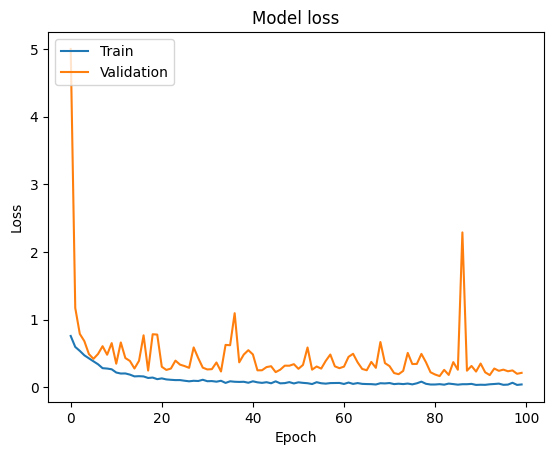

In [ ]:
# Plot training & validation loss values
plt.plot(history_1d.history['loss'])
plt.plot(history_1d.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
#Predict train
y_predict_1d_train = np.round(model1d.predict(X_train_1d))
cm_1d_train = confusion_matrix(Y_train, np.round(y_predict_1d_train))
cm_1d_train

178/178 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step


array([[2279,    0],
       [   2, 3392]])

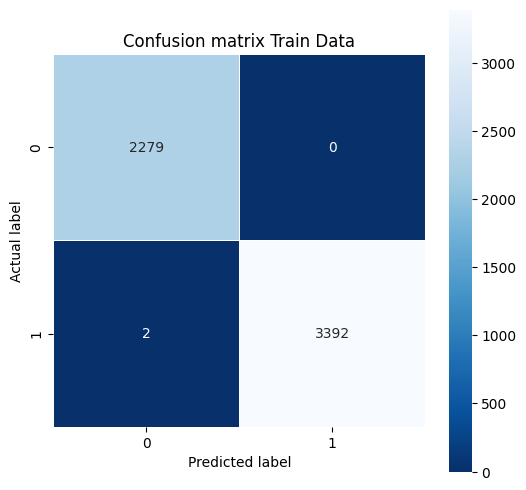

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_1d_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix Train Data')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_1d_train = classification_report(y_predict_1d_train, Y_train)
print("CNN Train Report:\n ",  report_1d_train)

CNN Train Report:
                precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      2281
         1.0       1.00      1.00      1.00      3392

    accuracy                           1.00      5673
   macro avg       1.00      1.00      1.00      5673
weighted avg       1.00      1.00      1.00      5673



In [ ]:
#Predict test
y_predict_1d_test = np.round(model1d.predict(X_test_1d))
cm_1d_test = confusion_matrix(Y_test, np.round(y_predict_1d_test))
cm_1d_test

45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step


array([[523,  55],
       [ 41, 800]])

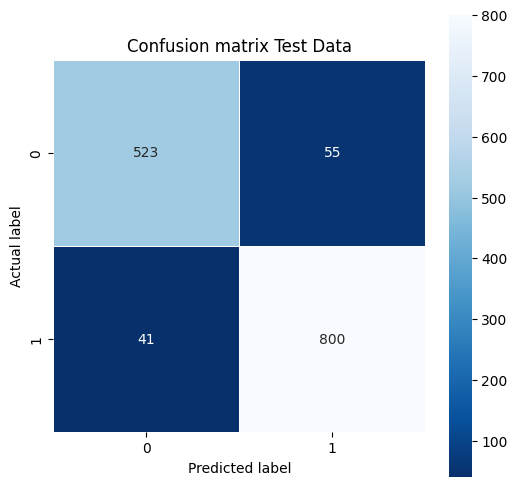

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_1d_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix Test Data')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_1d_test = classification_report(y_predict_1d_test, Y_test)
print("CNN Test Report:\n ", report_1d_test)

CNN Test Report:
                precision    recall  f1-score   support

         0.0       0.90      0.93      0.92       564
         1.0       0.95      0.94      0.94       855

    accuracy                           0.93      1419
   macro avg       0.93      0.93      0.93      1419
weighted avg       0.93      0.93      0.93      1419



In [ ]:
model1d.save('/content/drive/MyDrive/CNN_1D.keras')

### LSTM

In [ ]:
X_train_lstm = X_train.reshape(-1, 576, 70)
X_test_lstm = X_test.reshape(-1, 576, 70)

In [ ]:
model_lstm = Sequential()

model_lstm.add(LSTM(units=256, input_shape=(576, 70)))
model_lstm.add(BatchNormalization())
model_lstm.add(Dropout(0.5))


model_lstm.add(Dense(100, activation='relu'))
model_lstm.add(BatchNormalization())
model_lstm.add(Dropout(0.3))

model_lstm.add(Dense(50, activation = 'relu'))
model_lstm.add(Dropout(0.3))

model_lstm.add(Dense(1, activation='sigmoid'))

In [ ]:
model_lstm.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_lstm.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                        │ (None, 256)                 │         334,848 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_15 (Dropout)                 │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 100)                 │          25,700 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 100)                 │             400 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_16 (Dropout)                 │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 50)                  │           5,050 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_17 (Dropout)                 │ (None, 50)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 367,073 (1.40 MB)

 Trainable params: 366,361 (1.40 MB)

 Non-trainable params: 712 (2.78 KB)

In [ ]:
history_lstm = model_lstm.fit(X_train_lstm, Y_train, epochs= 100, batch_size= 32, validation_data=(X_test_lstm, Y_test))

Epoch 1/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 174s 961ms/step - accuracy: 0.4849 - loss: 0.9154 - val_accuracy: 0.5927 - val_loss: 0.6751
Epoch 2/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 171s 962ms/step - accuracy: 0.5460 - loss: 0.7390 - val_accuracy: 0.5934 - val_loss: 1.0038
Epoch 3/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 175s 985ms/step - accuracy: 0.5586 - loss: 0.7164 - val_accuracy: 0.5934 - val_loss: 0.7255
Epoch 4/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 173s 969ms/step - accuracy: 0.5592 - loss: 0.7026 - val_accuracy: 0.4080 - val_loss: 0.9319
Epoch 5/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 172s 967ms/step - accuracy: 0.5779 - loss: 0.6822 - val_accuracy: 0.5765 - val_loss: 0.7025
Epoch 6/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 171s 963ms/step - accuracy: 0.5708 - loss: 0.6925 - val_accuracy: 0.5976 - val_loss: 0.6742
Epoch 7/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 173s 970ms/step - accuracy: 0.5834 - loss: 0.6767 - val_accuracy: 0.5927 - val_loss: 0.8129
Epoch 8/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 172s 964ms/step - accuracy: 

In [ ]:
model_lstm.evaluate(X_test_lstm, Y_test)

45/45 ━━━━━━━━━━━━━━━━━━━━ 16s 349ms/step - accuracy: 0.5514 - loss: 0.7297


[0.7200769186019897, 0.5510923266410828]

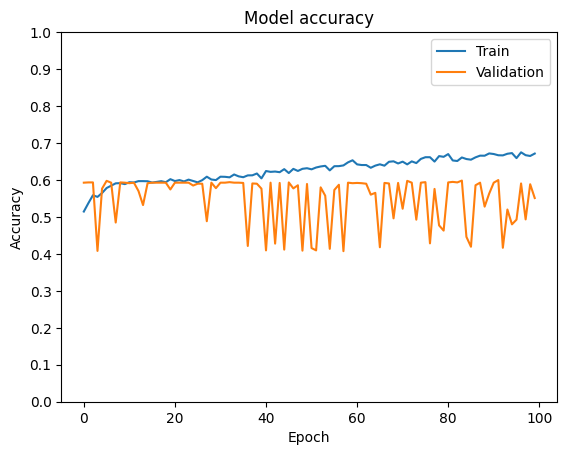

In [ ]:
# Plot training & validation accuracy values
plt.plot(history_lstm.history['accuracy'])
plt.plot(history_lstm.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([0,.10,.20,.30,.40,.50,.60,.70,.80,.90,1])
plt.legend(['Train', 'Validation'])
plt.show()

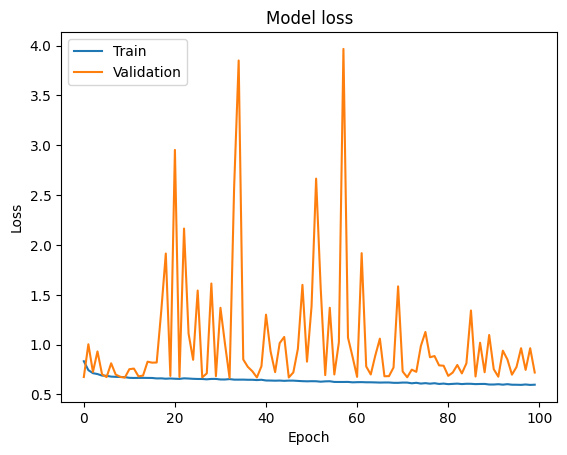

In [ ]:
# Plot training & validation loss values
plt.plot(history_lstm.history['loss'])
plt.plot(history_lstm.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
#Predict train
y_predict_lstm_train = np.round(model_lstm.predict(X_train_lstm))
cm_lstm_train = confusion_matrix(Y_train, np.round(y_predict_lstm_train))
cm_lstm_train

178/178 ━━━━━━━━━━━━━━━━━━━━ 32s 180ms/step


array([[ 692, 1587],
       [ 690, 2704]])

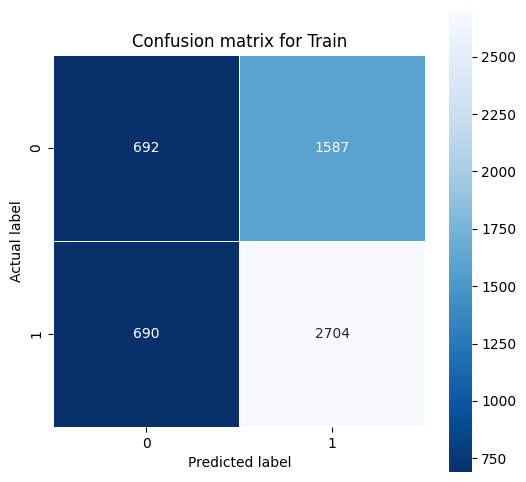

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_lstm_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for Train')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_lstm_train = classification_report(y_predict_lstm_train, Y_train)
print("LSTM Train Report:\n ",  report_lstm_train)

LSTM Train Report:
                precision    recall  f1-score   support

         0.0       0.30      0.50      0.38      1382
         1.0       0.80      0.63      0.70      4291

    accuracy                           0.60      5673
   macro avg       0.55      0.57      0.54      5673
weighted avg       0.68      0.60      0.62      5673



In [ ]:
#Predict train
y_predict_lstm_test = np.round(model_lstm.predict(X_test_lstm))
cm_lstm_test = confusion_matrix(Y_test, np.round(y_predict_lstm_test))
cm_lstm_test

45/45 ━━━━━━━━━━━━━━━━━━━━ 8s 180ms/step


array([[152, 426],
       [211, 630]])

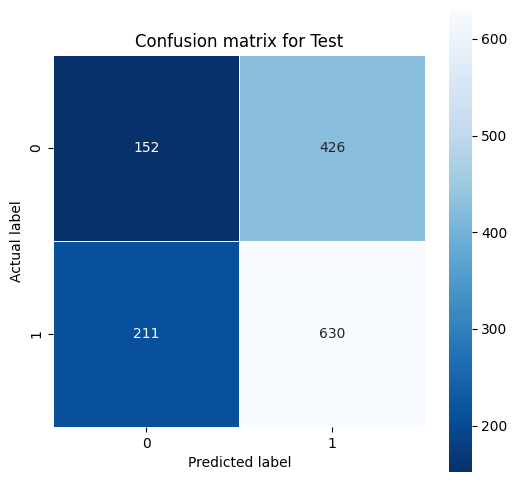

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_lstm_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for Test')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_lstm_test = classification_report(y_predict_lstm_test, Y_test)
print("LSTM Test Report:\n ",  report_lstm_test)

LSTM Test Report:
                precision    recall  f1-score   support

         0.0       0.26      0.42      0.32       363
         1.0       0.75      0.60      0.66      1056

    accuracy                           0.55      1419
   macro avg       0.51      0.51      0.49      1419
weighted avg       0.62      0.55      0.58      1419



In [ ]:
model_lstm.save('/content/drive/MyDrive/LSTM.keras')

##GRU

In [ ]:
X_train_gru = X_train.reshape(-1, 576, 70)
X_test_gru = X_test.reshape(-1, 576, 70)

In [ ]:
model_gru = Sequential()

model_gru.add(GRU(units=256, input_shape=(576, 70)))
model_gru.add(BatchNormalization())
model_gru.add(Dropout(0.5))

model_gru.add(Dense(100, activation='relu'))
model_gru.add(Dropout(0.3))

model_gru.add(Dense(50, activation = 'relu'))
model_gru.add(Dropout(0.3))

model_gru.add(Dense(1, activation='sigmoid'))

In [ ]:
model_gru.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_gru.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru_1 (GRU)                          │ (None, 256)                 │         251,904 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_6                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_18 (Dropout)                 │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 100)                 │          25,700 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_19 (Dropout)                 │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_19 (Dense)                     │ (None, 50)                  │           5,050 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_20 (Dropout)                 │ (None, 50)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_20 (Dense)                     │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 283,729 (1.08 MB)

 Trainable params: 283,217 (1.08 MB)

 Non-trainable params: 512 (2.00 KB)

In [ ]:
history_gru = model_gru.fit(X_train_gru, Y_train, epochs= 100, batch_size= 32, validation_data=(X_test_gru, Y_test))

Epoch 1/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 146s 803ms/step - accuracy: 0.5452 - loss: 0.7162 - val_accuracy: 0.5927 - val_loss: 0.6862
Epoch 2/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 143s 801ms/step - accuracy: 0.5705 - loss: 0.6934 - val_accuracy: 0.5856 - val_loss: 0.6828
Epoch 3/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 142s 800ms/step - accuracy: 0.5872 - loss: 0.6754 - val_accuracy: 0.5941 - val_loss: 0.6771
Epoch 4/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 143s 802ms/step - accuracy: 0.5759 - loss: 0.6785 - val_accuracy: 0.5934 - val_loss: 0.6714
Epoch 5/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 142s 800ms/step - accuracy: 0.6003 - loss: 0.6746 - val_accuracy: 0.5920 - val_loss: 0.6705
Epoch 6/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 142s 800ms/step - accuracy: 0.5974 - loss: 0.6663 - val_accuracy: 0.5941 - val_loss: 0.6658
Epoch 7/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 141s 793ms/step - accuracy: 0.5836 - loss: 0.6658 - val_accuracy: 0.5941 - val_loss: 0.6698
Epoch 8/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 147s 829ms/step - accuracy: 

In [ ]:
model_gru.evaluate(X_test_gru, Y_test)

45/45 ━━━━━━━━━━━━━━━━━━━━ 12s 262ms/step - accuracy: 0.9660 - loss: 0.1516


[0.12482918798923492, 0.9661733508110046]

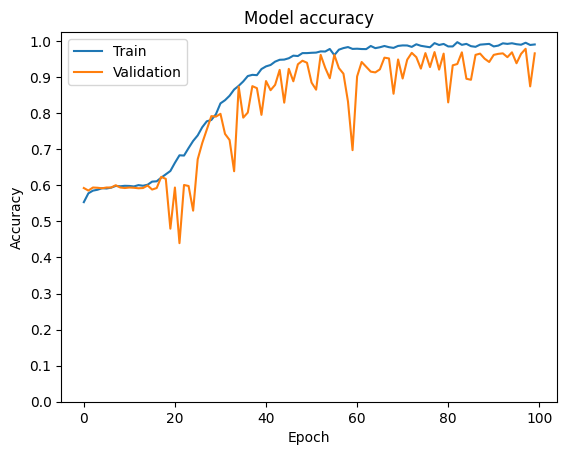

In [ ]:
# Plot training & validation accuracy values
plt.plot(history_gru.history['accuracy'])
plt.plot(history_gru.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([0,.10,.20,.30,.40,.50,.60,.70,.80,.90,1])
plt.legend(['Train', 'Validation'])
plt.show()

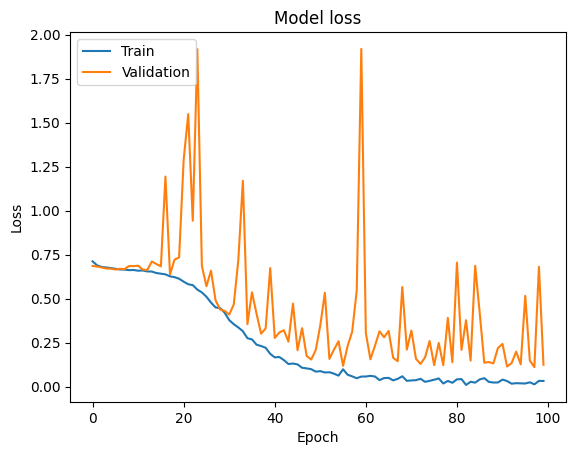

In [ ]:
# Plot training & validation loss values
plt.plot(history_gru.history['loss'])
plt.plot(history_gru.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
#Predict train
y_predict_gru_train = np.round(model_gru.predict(X_train_gru))
cm_gru_train = confusion_matrix(Y_train, np.round(y_predict_gru_train))
cm_gru_train

178/178 ━━━━━━━━━━━━━━━━━━━━ 28s 158ms/step


array([[2274,    5],
       [   8, 3386]])

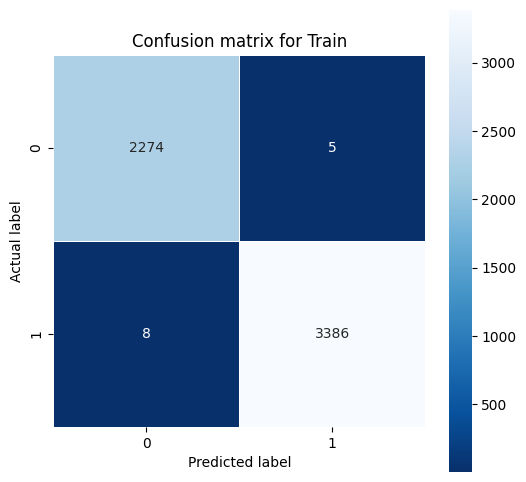

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_gru_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for Train')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_gru_train = classification_report(y_predict_gru_train, Y_train)
print("GRU Train Report:\n ",  report_gru_train)

GRU Train Report:
                precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      2282
         1.0       1.00      1.00      1.00      3391

    accuracy                           1.00      5673
   macro avg       1.00      1.00      1.00      5673
weighted avg       1.00      1.00      1.00      5673



In [ ]:
#Predict train
y_predict_gru_test = np.round(model_gru.predict(X_test_gru))
cm_gru_test = confusion_matrix(Y_test, np.round(y_predict_gru_test))
cm_gru_test

45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 143ms/step


array([[562,  16],
       [ 32, 809]])

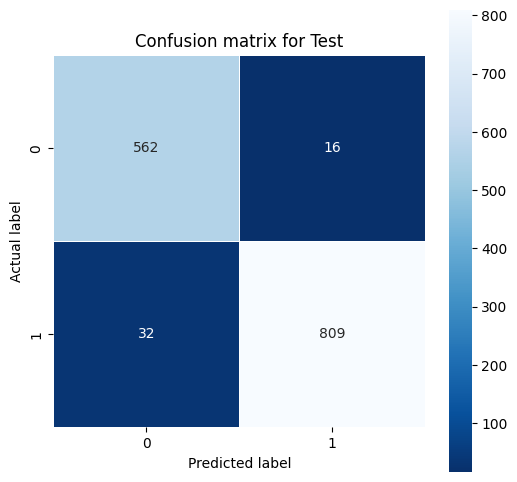

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_gru_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for Test')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_gru_test = classification_report(y_predict_gru_test, Y_test)
print("GRU Test Report:\n ",  report_gru_test)

GRU Test Report:
                precision    recall  f1-score   support

         0.0       0.97      0.95      0.96       594
         1.0       0.96      0.98      0.97       825

    accuracy                           0.97      1419
   macro avg       0.97      0.96      0.97      1419
weighted avg       0.97      0.97      0.97      1419



In [ ]:
model_gru.save('/content/drive/MyDrive/CNN_gru.keras')

### CNN_LSTM

In [ ]:
X_train_cnn_lstm = X_train.reshape(-1, 576, 70)
X_test_cnn_lstm = X_test.reshape(-1,576, 70)

In [ ]:
model = Sequential()


model.add(Conv1D(filters=64, kernel_size=5, activation='relu', input_shape=(576, 70)))
model.add(BatchNormalization())
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.3))


model.add(Conv1D(filters=128, kernel_size=3, activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.4))


model.add(Conv1D(filters=256, kernel_size=3, activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.4))


model.add(LSTM(units=128, return_sequences=True))
model.add(Dropout(0.3))
model.add(LSTM(units=128, return_sequences=False))
model.add(Dropout(0.3))


model.add(Flatten())

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(1, activation='sigmoid'))

In [ ]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_11 (Conv1D)                   │ (None, 572, 64)             │          22,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_11               │ (None, 572, 64)             │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_11 (MaxPooling1D)      │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_18 (Dropout)                 │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_12 (Conv1D)                   │ (None, 284, 128)            │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_12               │ (None, 284, 128)            │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_12 (MaxPooling1D)      │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_19 (Dropout)                 │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_13 (Conv1D)                   │ (None, 140, 256)            │          98,560 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_13               │ (None, 140, 256)            │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_13 (MaxPooling1D)      │ (None, 70, 256)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_20 (Dropout)                 │ (None, 70, 256)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_4 (LSTM)                        │ (None, 70, 128)             │         197,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_21 (Dropout)                 │ (None, 70, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_5 (LSTM)                        │ (None, 128)                 │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_22 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_4 (Flatten)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_23 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 1)                   │             1

 Total params: 492,865 (1.88 MB)

 Trainable params: 491,969 (1.88 MB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
history_cl = model.fit(X_train_cnn_lstm, Y_train, epochs=100, batch_size=32, validation_data=(X_test_cnn_lstm, Y_test))

Epoch 1/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 47s 239ms/step - accuracy: 0.5892 - loss: 0.6731 - val_accuracy: 0.4087 - val_loss: 0.7192
Epoch 2/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 39s 220ms/step - accuracy: 0.6471 - loss: 0.6402 - val_accuracy: 0.6216 - val_loss: 0.6497
Epoch 3/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 39s 222ms/step - accuracy: 0.6771 - loss: 0.6218 - val_accuracy: 0.6765 - val_loss: 0.6118
Epoch 4/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 41s 229ms/step - accuracy: 0.6877 - loss: 0.5957 - val_accuracy: 0.7019 - val_loss: 0.5748
Epoch 5/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 40s 227ms/step - accuracy: 0.7290 - loss: 0.5516 - val_accuracy: 0.6970 - val_loss: 0.5876
Epoch 6/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 40s 225ms/step - accuracy: 0.7200 - loss: 0.5654 - val_accuracy: 0.7463 - val_loss: 0.5376
Epoch 7/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 40s 225ms/step - accuracy: 0.7619 - loss: 0.4988 - val_accuracy: 0.6878 - val_loss: 0.6265
Epoch 8/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 39s 218ms/step - accuracy: 0.7837 -

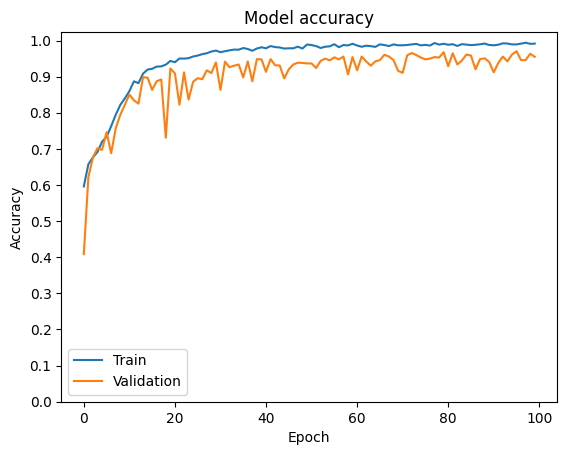

In [ ]:
# Plot training & validation accuracy values
plt.plot(history_cl.history['accuracy'])
plt.plot(history_cl.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([0,.10,.20,.30,.40,.50,.60,.70,.80,.90,1])
plt.legend(['Train', 'Validation'])
plt.show()

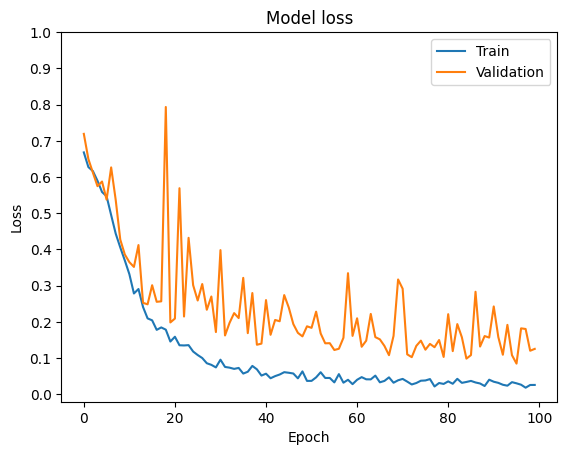

In [ ]:
# Plot training & validation loss values
plt.plot(history_cl.history['loss'])
plt.plot(history_cl.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.yticks([0,.10,.20,.30,.40,.50,.60,.70,.80,.90,1])
plt.legend(['Train', 'Validation'])
plt.show()

In [ ]:
#Predict train
y_predict_cl_train = np.round(model.predict(X_train_cnn_lstm))
cm_cl_train = confusion_matrix(Y_train, np.round(y_predict_cl_train))
cm_cl_train

178/178 ━━━━━━━━━━━━━━━━━━━━ 15s 82ms/step


array([[2277,    2],
       [  42, 3352]])

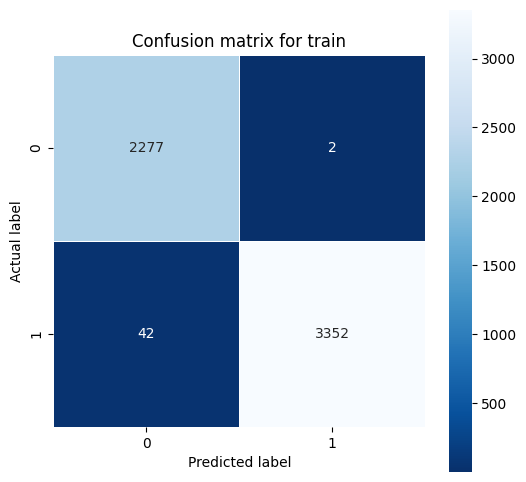

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_cl_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for train')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_cnn_lstm_train = classification_report(y_predict_cl_train, Y_train)
print("Report for Train: \n", report_cnn_lstm_train)

Report for Train: 
               precision    recall  f1-score   support

         0.0       1.00      0.98      0.99      2319
         1.0       0.99      1.00      0.99      3354

    accuracy                           0.99      5673
   macro avg       0.99      0.99      0.99      5673
weighted avg       0.99      0.99      0.99      5673



In [ ]:
#Predict test
y_predict_cl_test = np.round(model.predict(X_test_cnn_lstm))
cm_cl_test = confusion_matrix(Y_test, np.round(y_predict_cl_test))
cm_cl_test

45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 74ms/step


array([[564,  14],
       [ 50, 791]])

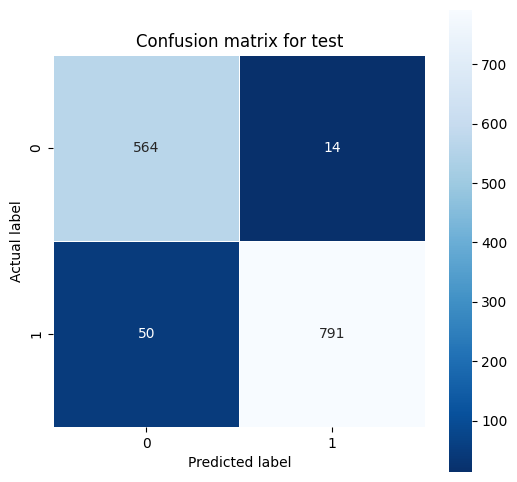

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_cl_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for test')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_cnn_lstm = classification_report(y_predict_cl_test, Y_test)
print("Report for Test:\n ", report_cnn_lstm)

Report for Test:
                precision    recall  f1-score   support

         0.0       0.98      0.92      0.95       614
         1.0       0.94      0.98      0.96       805

    accuracy                           0.95      1419
   macro avg       0.96      0.95      0.95      1419
weighted avg       0.96      0.95      0.95      1419



In [ ]:
model.save("/content/drive/MyDrive/cnn_lstm.keras")

### CNN_SVM

In [ ]:
X_train_cs = X_train.reshape(-1, 576, 70)
X_test_cs = X_test.reshape(-1, 576, 70)

In [ ]:
model_cs = Sequential()


model_cs.add(Conv1D(filters=64, kernel_size=5, activation='relu', input_shape=(576, 70)))
model_cs.add(BatchNormalization())
model_cs.add(MaxPooling1D(pool_size=2))
model_cs.add(Dropout(0.3))


model_cs.add(Conv1D(filters=128, kernel_size=3, activation='relu'))
model_cs.add(BatchNormalization())
model_cs.add(MaxPooling1D(pool_size=2))
model_cs.add(Dropout(0.4))

model_cs.add(Flatten())

feature = Model(inputs=model_cs.inputs, outputs=model_cs.layers[-1].output)

In [ ]:
X_train_f = feature.predict(X_train_cs)
X_test_f = feature.predict(X_test_cs)

178/178 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


In [ ]:
sc = StandardScaler()
X_train_s = sc.fit_transform(X_train_f)
X_test_s = sc.transform(X_test_f)

In [ ]:
pca = PCA(n_components=0.85)
X_train_pca = pca.fit_transform(X_train_s)
X_test_pca = pca.transform(X_test_s)

In [ ]:
SVM = make_pipeline(StandardScaler(), SVC(kernel='linear'))

In [ ]:
SVM.fit(X_train_pca, Y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(kernel='linear'))])

In [ ]:
#predict test
y_pred_cs_test = SVM.predict(X_test_pca)
accuracy = accuracy_score(Y_test, y_pred_cs_test)
print("CNN_SVM Test Accuracy: ",accuracy)

CNN_SVM Test Accuracy:  0.6645525017618041


In [ ]:
cm_cs = confusion_matrix(Y_test, y_pred_cs_test)
print(cm_cs)

[[298 280]
 [196 645]]


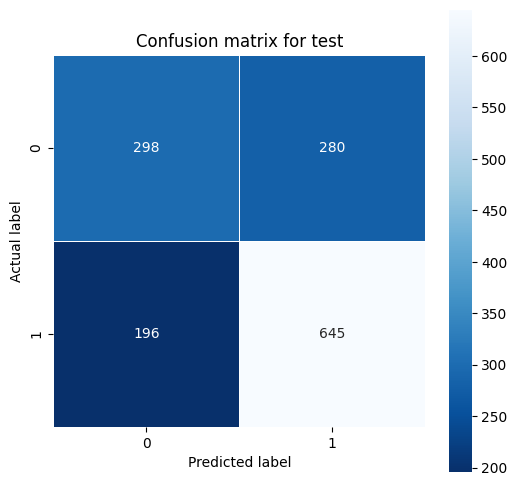

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_cs, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for test')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_cs_test = classification_report(Y_test, y_pred_cs_test)
print("Report for Test :\n", report_cs_test)

Report for Test :
               precision    recall  f1-score   support

         0.0       0.60      0.52      0.56       578
         1.0       0.70      0.77      0.73       841

    accuracy                           0.66      1419
   macro avg       0.65      0.64      0.64      1419
weighted avg       0.66      0.66      0.66      1419



In [ ]:
#predict train
y_pred_svm_train = SVM.predict(X_train_pca)
accuracy_train = accuracy_score(Y_train, y_pred_svm_train)
print("CNN_SVM  Train Accuracy:", accuracy_train)

CNN_SVM  Train Accuracy: 0.8468182619425348


In [ ]:
cm_cs_train = confusion_matrix(Y_train, y_pred_svm_train)
print(cm_cs_train)

[[1794  485]
 [ 384 3010]]


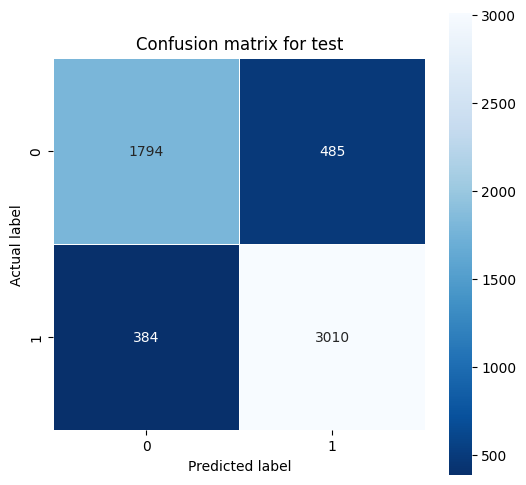

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_cs_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for train')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_cs_train = classification_report(Y_train, y_pred_svm_train)
print("Report for Train :\n", report_cs_train)

Report for Train :
               precision    recall  f1-score   support

         0.0       0.82      0.79      0.81      2279
         1.0       0.86      0.89      0.87      3394

    accuracy                           0.85      5673
   macro avg       0.84      0.84      0.84      5673
weighted avg       0.85      0.85      0.85      5673



In [ ]:
# Save the CNN model
model_cs.save('cnn_svm.keras')

# Save the SVM classifier
joblib.dump(SVM, 'svm.pkl')

['svm.pkl']

### CNN_RNN

In [ ]:
model_cr = Sequential()

model_cr.add(Conv1D(filters=64, kernel_size=5, activation='relu', input_shape=(576, 70)))
model_cr.add(BatchNormalization())
model_cr.add(MaxPooling1D(pool_size=2))
model_cr.add(Dropout(0.3))

model_cr.add(Conv1D(filters=128, kernel_size=3, activation='relu'))
model_cr.add(BatchNormalization())
model_cr.add(MaxPooling1D(pool_size=2))
model_cr.add(Dropout(0.4))

model_cr.add(Conv1D(filters=128, kernel_size=3, activation='relu'))
model_cr.add(BatchNormalization())
model_cr.add(MaxPooling1D(pool_size=2))
model_cr.add(Dropout(0.4))

model_cr.add(SimpleRNN(units=128, return_sequences=True))
model_cr.add(Dropout(0.3))

model_cr.add(SimpleRNN(units=128, return_sequences=False))
model_cr.add(Dropout(0.3))

model_cr.add(Flatten())


model_cr.add(Dense(128, activation='relu'))
model_cr.add(Dropout(0.3))

model_cr.add(Dense(1, activation='sigmoid'))

In [ ]:
model_cr.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_cr.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_9 (Conv1D)                    │ (None, 572, 64)             │          22,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_11               │ (None, 572, 64)             │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_9 (MaxPooling1D)       │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_19 (Dropout)                 │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_10 (Conv1D)                   │ (None, 284, 128)            │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_12               │ (None, 284, 128)            │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_10 (MaxPooling1D)      │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_20 (Dropout)                 │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_11 (Conv1D)                   │ (None, 140, 128)            │          49,280 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_13               │ (None, 140, 128)            │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_11 (MaxPooling1D)      │ (None, 70, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_21 (Dropout)                 │ (None, 70, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_4 (SimpleRNN)             │ (None, 70, 128)             │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_22 (Dropout)                 │ (None, 70, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_5 (SimpleRNN)             │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_23 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_3 (Flatten)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_24 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 1)                   │             1

 Total params: 180,161 (703.75 KB)

 Trainable params: 179,521 (701.25 KB)

 Non-trainable params: 640 (2.50 KB)

In [ ]:
history_cr = model_cr.fit(X_train_cnn_lstm, Y_train, epochs=100, batch_size= 32, validation_data=(X_test_cnn_lstm, Y_test))

Epoch 1/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 25s 105ms/step - accuracy: 0.5498 - loss: 0.7362 - val_accuracy: 0.4080 - val_loss: 0.9437
Epoch 2/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 18s 104ms/step - accuracy: 0.5666 - loss: 0.6948 - val_accuracy: 0.4567 - val_loss: 0.7508
Epoch 3/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 18s 100ms/step - accuracy: 0.5911 - loss: 0.6813 - val_accuracy: 0.5645 - val_loss: 0.6868
Epoch 4/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 21s 120ms/step - accuracy: 0.6053 - loss: 0.6752 - val_accuracy: 0.5617 - val_loss: 0.7075
Epoch 5/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 19s 106ms/step - accuracy: 0.6022 - loss: 0.6727 - val_accuracy: 0.5539 - val_loss: 0.6789
Epoch 6/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 19s 106ms/step - accuracy: 0.5927 - loss: 0.6731 - val_accuracy: 0.5863 - val_loss: 0.7262
Epoch 7/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 18s 101ms/step - accuracy: 0.5558 - loss: 0.7185 - val_accuracy: 0.5300 - val_loss: 0.6973
Epoch 8/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 18s 102ms/step - accuracy: 0.5923 -

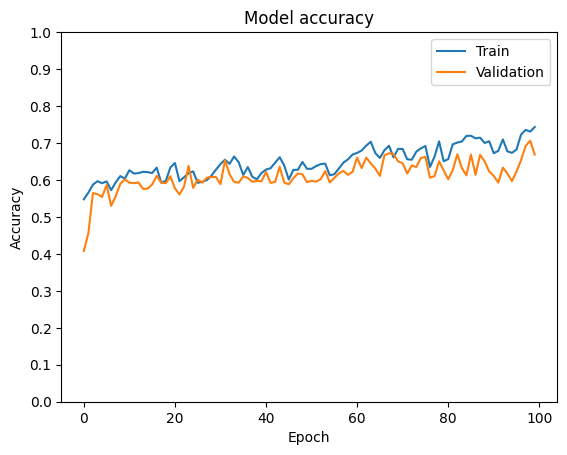

In [ ]:
# Plot training & validation accuracy values
plt.plot(history_cr.history['accuracy'])
plt.plot(history_cr.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([0,.10,.20,.30,.40,.50,.60,.70,.80,.90,1])
plt.legend(['Train', 'Validation'])
plt.show()

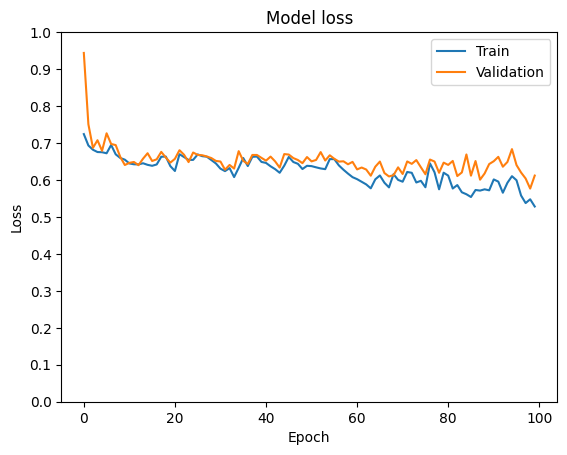

In [ ]:
# Plot training & validation loss values
plt.plot(history_cr.history['loss'])
plt.plot(history_cr.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.yticks([0,.10,.20,.30,.40,.50,.60,.70,.80,.90,1])
plt.legend(['Train', 'Validation'])
plt.show()

In [ ]:
#Predict train
y_predict_cr_train = np.round(model_cr.predict(X_train_cnn_lstm))
cm_cr_train = confusion_matrix(Y_train, np.round(y_predict_cr_train))
cm_cr_train

178/178 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step


array([[1322,  957],
       [ 626, 2768]])

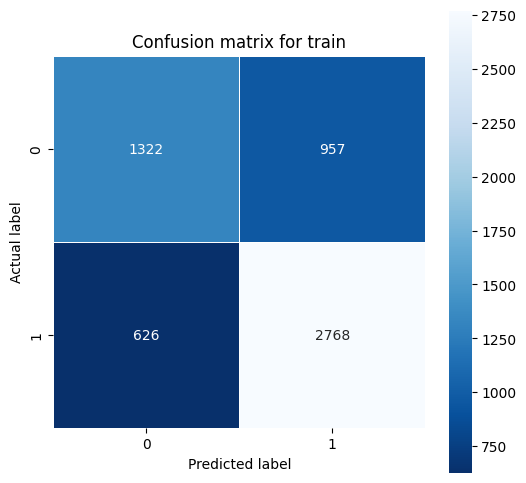

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_cr_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for train')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_crt = classification_report(y_predict_cr_train, Y_train)
print("Report for Train:\n ", report_crt)

Report for Train:
                precision    recall  f1-score   support

         0.0       0.58      0.68      0.63      1948
         1.0       0.82      0.74      0.78      3725

    accuracy                           0.72      5673
   macro avg       0.70      0.71      0.70      5673
weighted avg       0.73      0.72      0.73      5673



In [ ]:
#Predict test
y_predict_cr_test = np.round(model_cr.predict(X_test_cnn_lstm))
cm_cr_test = confusion_matrix(Y_test, np.round(y_predict_cr_test))
cm_cr_test

45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step


array([[294, 284],
       [186, 655]])

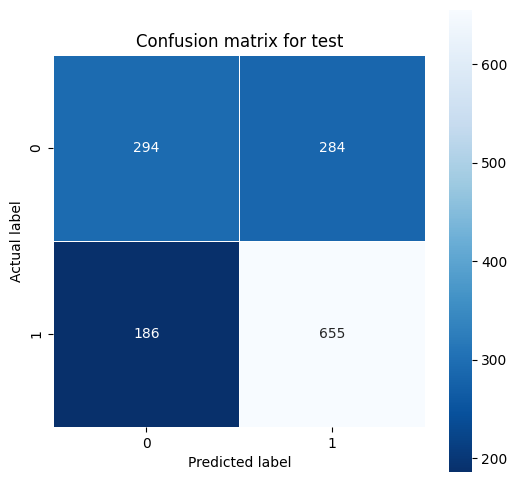

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_cr_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for test')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_cr = classification_report(y_predict_cr_test, Y_test)
print("Report for Test:\n ", report_cr)

Report for Test:
                precision    recall  f1-score   support

         0.0       0.51      0.61      0.56       480
         1.0       0.78      0.70      0.74       939

    accuracy                           0.67      1419
   macro avg       0.64      0.66      0.65      1419
weighted avg       0.69      0.67      0.68      1419



In [ ]:
model_cr.save("/content/drive/MyDrive/cnn_rnn.keras")

### CNN_GRU

In [ ]:
model_cg = Sequential()


model_cg.add(Conv1D(filters=64, kernel_size=5, activation='relu', input_shape=(576, 70)))
model_cg.add(BatchNormalization())
model_cg.add(MaxPooling1D(pool_size=2))
model_cg.add(Dropout(0.3))


model_cg.add(Conv1D(filters=128, kernel_size=3, activation='relu'))
model_cg.add(BatchNormalization())
model_cg.add(MaxPooling1D(pool_size=2))
model_cg.add(Dropout(0.4))

model_cg.add(Conv1D(filters=256, kernel_size=3, activation='relu', kernel_regularizer=l2(0.01)))
model_cg.add(BatchNormalization())
model_cg.add(MaxPooling1D(pool_size=2))
model_cg.add(Dropout(0.4))

model_cg.add(GRU(units=128, return_sequences=True))
model_cg.add(BatchNormalization())
model_cg.add(Dropout(0.3))


model_cg.add(GRU(units=128, return_sequences=False))
model_cg.add(BatchNormalization())
model_cg.add(Dropout(0.3))

model_cg.add(Flatten())

model_cg.add(Dense(128, activation='relu', kernel_regularizer=l2(0.01)))
model_cg.add(Dropout(0.3))

model_cg.add(Dense(1, activation='sigmoid'))


In [ ]:
model_cg.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_cg.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_3 (Conv1D)                    │ (None, 572, 64)             │          22,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 572, 64)             │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_3 (MaxPooling1D)       │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_4 (Conv1D)                    │ (None, 284, 128)            │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 284, 128)            │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_4 (MaxPooling1D)       │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_5 (Conv1D)                    │ (None, 140, 256)            │          98,560 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 140, 256)            │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_5 (MaxPooling1D)       │ (None, 70, 256)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 70, 256)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ (None, 70, 256)             │         296,448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_6                │ (None, 70, 256)             │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_9 (Dropout)                  │ (None, 70, 256)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional_1 (Bidirectional)      │ (None, 256)                 │         296,448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_7                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_10 (Dropout)                 │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 256)                 │              

 Total params: 775,489 (2.96 MB)

 Trainable params: 773,569 (2.95 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [ ]:
history_cg = model_cg.fit(X_train_cnn_lstm, Y_train, epochs=100, batch_size=32, validation_data=(X_test_cnn_lstm, Y_test))

Epoch 1/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 58s 256ms/step - accuracy: 0.5507 - loss: 3.7941 - val_accuracy: 0.5208 - val_loss: 2.5215
Epoch 2/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 47s 266ms/step - accuracy: 0.5791 - loss: 2.2628 - val_accuracy: 0.5130 - val_loss: 1.6309
Epoch 3/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 44s 244ms/step - accuracy: 0.6385 - loss: 1.4374 - val_accuracy: 0.4623 - val_loss: 1.2601
Epoch 4/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 45s 253ms/step - accuracy: 0.6828 - loss: 0.9914 - val_accuracy: 0.6490 - val_loss: 0.9222
Epoch 5/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 51s 285ms/step - accuracy: 0.7514 - loss: 0.7358 - val_accuracy: 0.7230 - val_loss: 0.6969
Epoch 6/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 62s 348ms/step - accuracy: 0.7947 - loss: 0.6131 - val_accuracy: 0.7696 - val_loss: 0.6341
Epoch 7/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 47s 264ms/step - accuracy: 0.8123 - loss: 0.5518 - val_accuracy: 0.7040 - val_loss: 0.7379
Epoch 8/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 43s 244ms/step - accuracy: 0.8472 -

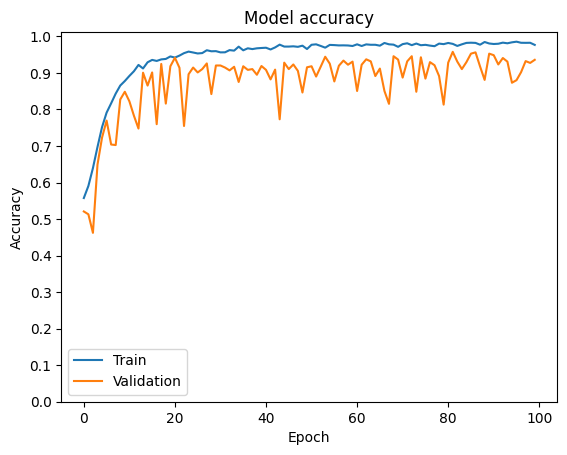

In [ ]:
# Plot training & validation accuracy values
plt.plot(history_cg.history['accuracy'])
plt.plot(history_cg.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([0,.10,.20,.30,.40,.50,.60,.70,.80,.90,1])
plt.legend(['Train', 'Validation'])
plt.show()

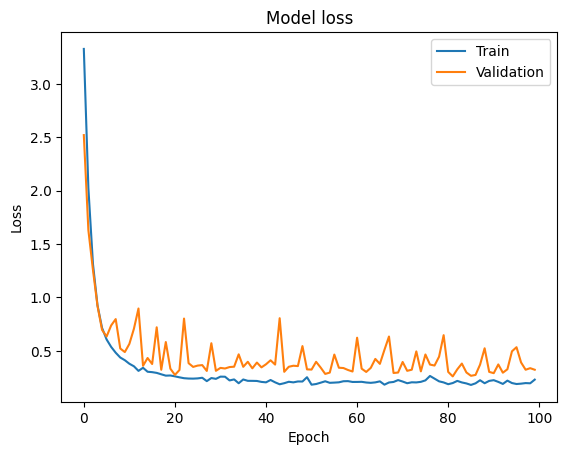

In [ ]:
# Plot training & validation loss values
plt.plot(history_cg.history['loss'])
plt.plot(history_cg.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'])
plt.show()

In [ ]:
#Predict train
y_predict_cg_train = np.round(model_cg.predict(X_train_cnn_lstm))
cm_cg_train = confusion_matrix(Y_train, np.round(y_predict_cg_train))
cm_cg_train

178/178 ━━━━━━━━━━━━━━━━━━━━ 12s 64ms/step


array([[2275,    4],
       [ 110, 3284]])

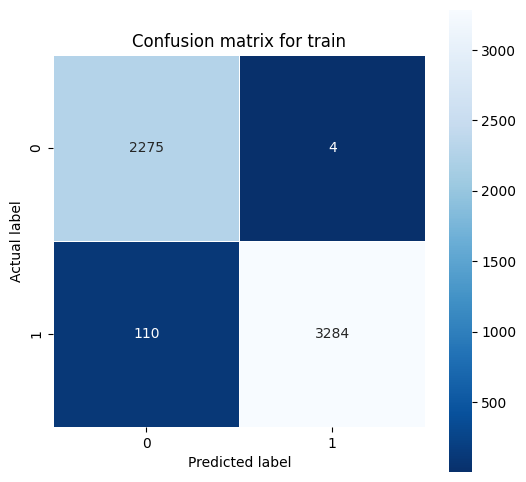

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_cg_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for train')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_cgt = classification_report(y_predict_cg_train, Y_train)
print("Report for Train:\n ", report_cgt)

Report for Train:
                precision    recall  f1-score   support

         0.0       1.00      0.95      0.98      2385
         1.0       0.97      1.00      0.98      3288

    accuracy                           0.98      5673
   macro avg       0.98      0.98      0.98      5673
weighted avg       0.98      0.98      0.98      5673



In [ ]:
#Predict test
y_predict_cg_test = np.round(model_cg.predict(X_test_cnn_lstm))
cm_cg_test = confusion_matrix(Y_test, np.round(y_predict_cg_test))
cm_cg_test

45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step


array([[556,  22],
       [ 69, 772]])

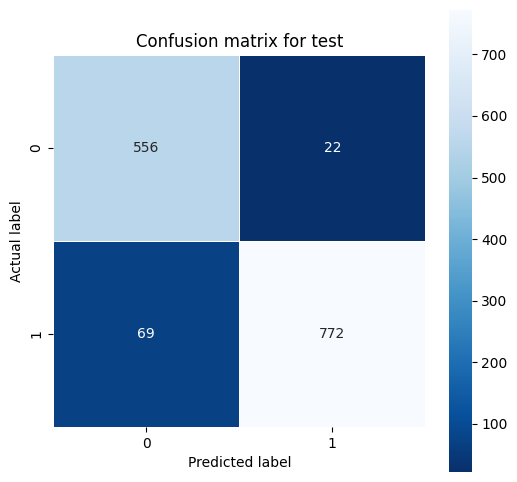

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_cg_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for test')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_cg = classification_report(y_predict_cg_test, Y_test)
print("Report for Test:\n ", report_cg)

Report for Test:
                precision    recall  f1-score   support

         0.0       0.96      0.89      0.92       625
         1.0       0.92      0.97      0.94       794

    accuracy                           0.94      1419
   macro avg       0.94      0.93      0.93      1419
weighted avg       0.94      0.94      0.94      1419



In [ ]:
model_cg.save("/content/drive/MyDrive/cnn_gru.keras")

### CNN + LSTM + GRU

In [ ]:
model_eeg = Sequential()


model_eeg.add(Conv1D(filters=64, kernel_size=5, activation='relu', input_shape=(576, 70)))
model_eeg.add(BatchNormalization())
model_eeg.add(MaxPooling1D(pool_size=2))
model_eeg.add(Dropout(0.3))


model_eeg.add(Conv1D(filters=128, kernel_size=3, activation='relu'))
model_eeg.add(BatchNormalization())
model_eeg.add(MaxPooling1D(pool_size=2))
model_eeg.add(Dropout(0.4))

model_eeg.add(Conv1D(filters=256, kernel_size=3, activation='relu', kernel_regularizer=l2(0.01)))
model_eeg.add(BatchNormalization())
model_eeg.add(MaxPooling1D(pool_size=2))
model_eeg.add(Dropout(0.4))

model_eeg.add(LSTM(units=128, return_sequences=True))
model_eeg.add(Dropout(0.3))

model_eeg.add(LSTM(units=128, return_sequences=True))
model_eeg.add(Dropout(0.3))


model_eeg.add(GRU(units=128, return_sequences=False))
model_eeg.add(BatchNormalization())
model_eeg.add(Dropout(0.3))

model_eeg.add(Flatten())

model_eeg.add(Dense(128, activation='relu', kernel_regularizer=l2(0.01)))
model_eeg.add(Dropout(0.3))

model_eeg.add(Dense(1, activation='sigmoid'))

In [ ]:
model_eeg.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_eeg.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_6 (Conv1D)                    │ (None, 572, 64)             │          22,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_10               │ (None, 572, 64)             │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_6 (MaxPooling1D)       │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_17 (Dropout)                 │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_7 (Conv1D)                    │ (None, 284, 128)            │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_11               │ (None, 284, 128)            │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_7 (MaxPooling1D)       │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_18 (Dropout)                 │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_8 (Conv1D)                    │ (None, 140, 256)            │          98,560 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_12               │ (None, 140, 256)            │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_8 (MaxPooling1D)       │ (None, 70, 256)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_19 (Dropout)                 │ (None, 70, 256)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_4 (LSTM)                        │ (None, 70, 128)             │         197,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_20 (Dropout)                 │ (None, 70, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_5 (LSTM)                        │ (None, 70, 128)             │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_21 (Dropout)                 │ (None, 70, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_5 (GRU)                          │ (None, 128)                 │          99,072 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_13               │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_22 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 592,449 (2.26 MB)

 Trainable params: 591,297 (2.26 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [ ]:
history_eeg = model_eeg.fit(X_train_1d, Y_train, epochs=101, batch_size=32, validation_data=(X_test_1d, Y_test))

Epoch 1/101
178/178 ━━━━━━━━━━━━━━━━━━━━ 51s 244ms/step - accuracy: 0.5473 - loss: 3.2274 - val_accuracy: 0.5927 - val_loss: 1.7560
Epoch 2/101
178/178 ━━━━━━━━━━━━━━━━━━━━ 43s 240ms/step - accuracy: 0.6192 - loss: 1.5186 - val_accuracy: 0.5934 - val_loss: 1.0704
Epoch 3/101
178/178 ━━━━━━━━━━━━━━━━━━━━ 43s 241ms/step - accuracy: 0.6604 - loss: 0.9528 - val_accuracy: 0.5398 - val_loss: 0.9519
Epoch 4/101
178/178 ━━━━━━━━━━━━━━━━━━━━ 42s 238ms/step - accuracy: 0.6421 - loss: 0.8590 - val_accuracy: 0.6124 - val_loss: 0.8880
Epoch 5/101
178/178 ━━━━━━━━━━━━━━━━━━━━ 42s 237ms/step - accuracy: 0.7360 - loss: 0.6285 - val_accuracy: 0.6934 - val_loss: 0.6640
Epoch 6/101
178/178 ━━━━━━━━━━━━━━━━━━━━ 44s 249ms/step - accuracy: 0.7861 - loss: 0.5373 - val_accuracy: 0.7992 - val_loss: 0.4832
Epoch 7/101
178/178 ━━━━━━━━━━━━━━━━━━━━ 43s 244ms/step - accuracy: 0.8345 - loss: 0.4328 - val_accuracy: 0.8259 - val_loss: 0.4389
Epoch 8/101
178/178 ━━━━━━━━━━━━━━━━━━━━ 43s 242ms/step - accuracy: 0.8554 -

In [ ]:
model_eeg.evaluate(X_test_1d, Y_test)

45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 74ms/step - accuracy: 0.9409 - loss: 0.2317


[0.23001417517662048, 0.9457364082336426]

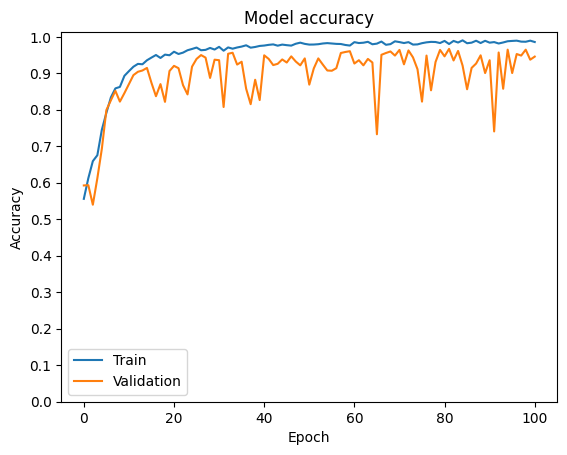

In [ ]:
# Plot training & validation accuracy values
plt.plot(history_eeg.history['accuracy'])
plt.plot(history_eeg.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([0,.10,.20,.30,.40,.50,.60,.70,.80,.90,1])
plt.legend(['Train', 'Validation'])
plt.show()

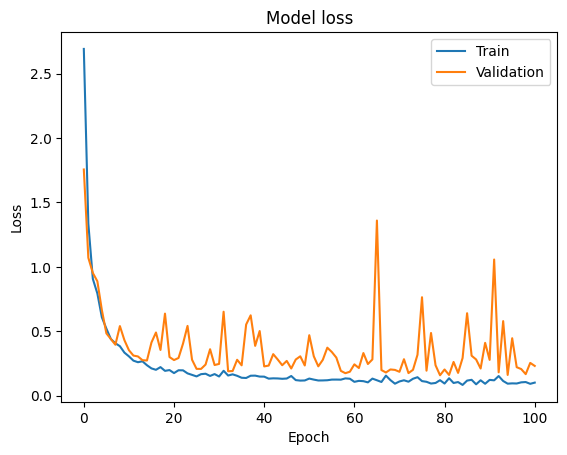

In [ ]:
# Plot training & validation loss values
plt.plot(history_eeg.history['loss'])
plt.plot(history_eeg.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'])
plt.show()

In [ ]:
#Predict train
y_predict_eeg_train = np.round(model_eeg.predict(X_train_1d))
cm_eeg_train = confusion_matrix(Y_train, np.round(y_predict_eeg_train))
cm_eeg_train

178/178 ━━━━━━━━━━━━━━━━━━━━ 14s 75ms/step


array([[2276,    3],
       [  48, 3346]])

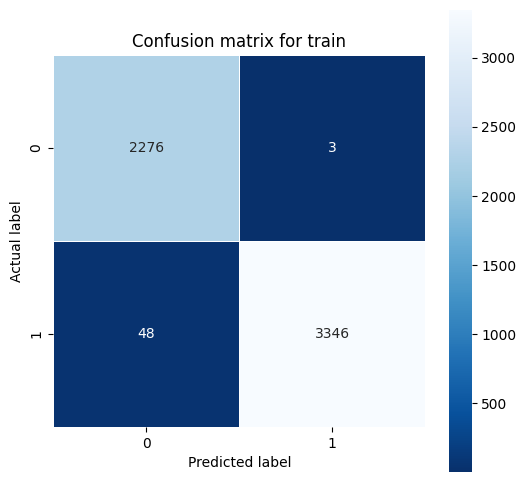

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_eeg_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for train')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_eegt = classification_report(y_predict_eeg_train, Y_train)
print("Report for Train:\n ", report_eegt)

Report for Train:
                precision    recall  f1-score   support

         0.0       1.00      0.98      0.99      2324
         1.0       0.99      1.00      0.99      3349

    accuracy                           0.99      5673
   macro avg       0.99      0.99      0.99      5673
weighted avg       0.99      0.99      0.99      5673



In [ ]:
#Predict test
y_predict_eeg_test = np.round(model_eeg.predict(X_test_1d))
cm_eeg_test = confusion_matrix(Y_test, np.round(y_predict_eeg_test))
cm_eeg_test

45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step


array([[560,  18],
       [ 59, 782]])

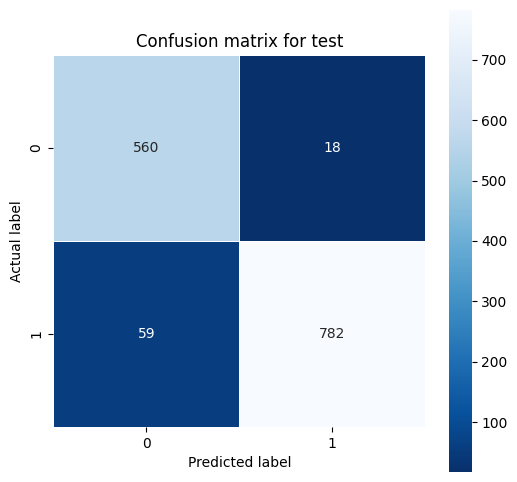

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_eeg_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for test')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_eeg = classification_report(y_predict_eeg_test, Y_test)
print("Report for Test:\n ", report_eeg)

Report for Test:
                precision    recall  f1-score   support

         0.0       0.97      0.90      0.94       619
         1.0       0.93      0.98      0.95       800

    accuracy                           0.95      1419
   macro avg       0.95      0.94      0.94      1419
weighted avg       0.95      0.95      0.95      1419



In [ ]:
model_eeg.save("/content/drive/MyDrive/CNN_LSTM_GRU.keras")

## Accuracy Plot

In [ ]:
dic = { 'Model' : ["CNN", "LSTM", "GRU", "CNN_RNN", "CNN_LSTM", "CNN_GRU", "CNN_SVM", "CNN_LSTM_GRU"],\
        "Train Accuracy" : [98.72, 68.01, 99.16, 75.28, 99.26, 97.36, 86.00, 98.61],\
      "Test Accuracy" : [93.27, 58.40, 96.62, 66.88, 95.49, 93.59, 66.00, 94.57]}

In [ ]:
df = pd.DataFrame(dic)
df

,Model,Train Accuracy,Test Accuracy
0,CNN,98.72,93.27
1,LSTM,68.01,58.40
2,GRU,99.16,96.62
3,CNN_RNN,75.28,66.88
4,CNN_LSTM,99.26,95.49
5,CNN_GRU,97.36,93.59
6,CNN_SVM,86.00,66.00
7,CNN_LSTM_GRU,98.61,94.57


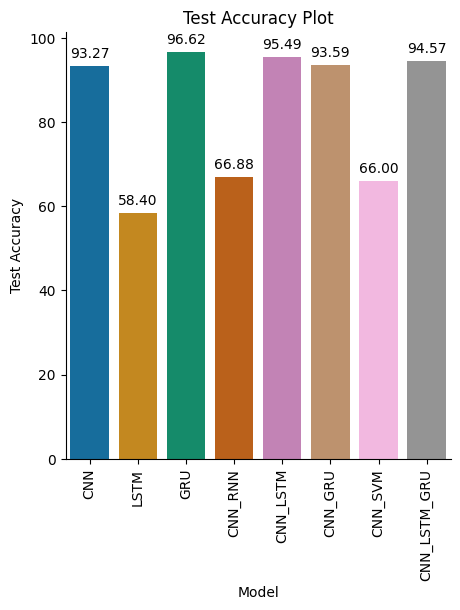

In [ ]:
test = sns.catplot(x="Model", y="Test Accuracy", data=df, kind="bar", palette="colorblind", legend=False)
plt.title("Test Accuracy Plot")
plt.xticks(rotation = 90)

ax = test.facet_axis(0, 0)

for i in ax.patches:
    ax.annotate(f'{i.get_height():.2f}', (i.get_x() + i.get_width() / 2., i.get_height()),
                ha='center', va='center', xytext=(0, 9), textcoords='offset points')

plt.show()

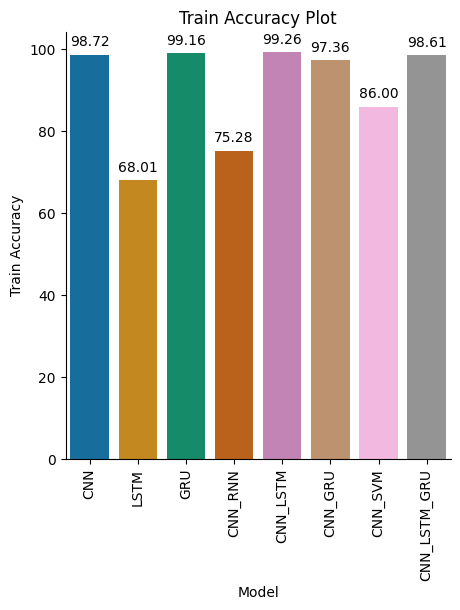

In [ ]:
train = sns.catplot(x="Model", y="Train Accuracy", data=df, kind="bar", palette="colorblind", legend=False)
plt.title("Train Accuracy Plot")
plt.xticks(rotation = 90)

ax = train.facet_axis(0, 0)

for i in ax.patches:
    ax.annotate(f'{i.get_height():.2f}', (i.get_x() + i.get_width() / 2., i.get_height()),
                ha='center', va='center', xytext=(0, 9), textcoords='offset points')

plt.show()

### ROC plot

In [17]:
CNN = load_model('/content/drive/MyDrive/Thesis/CNN_1D.keras')
LSTM = load_model('/content/drive/MyDrive/Thesis/LSTM.keras')
GRU = load_model('/content/drive/MyDrive/Thesis/GRU.keras')
CNN_RNN = load_model('/content/drive/MyDrive/Thesis/cnn_rnn.keras')
CNN_LSTM = load_model('/content/drive/MyDrive/Thesis/cnn_lstm.keras')
CNN_GRU = load_model('/content/drive/MyDrive/Thesis/cnn_gru.keras')
CNN_LSTM_GRU = load_model('/content/drive/MyDrive/Thesis/CNN_LSTM_GRU.keras')

178/178 ━━━━━━━━━━━━━━━━━━━━ 14s 73ms/step
178/178 ━━━━━━━━━━━━━━━━━━━━ 101s 569ms/step
178/178 ━━━━━━━━━━━━━━━━━━━━ 76s 423ms/step
178/178 ━━━━━━━━━━━━━━━━━━━━ 15s 81ms/step
178/178 ━━━━━━━━━━━━━━━━━━━━ 26s 142ms/step
178/178 ━━━━━━━━━━━━━━━━━━━━ 36s 198ms/step
178/178 ━━━━━━━━━━━━━━━━━━━━ 29s 159ms/step


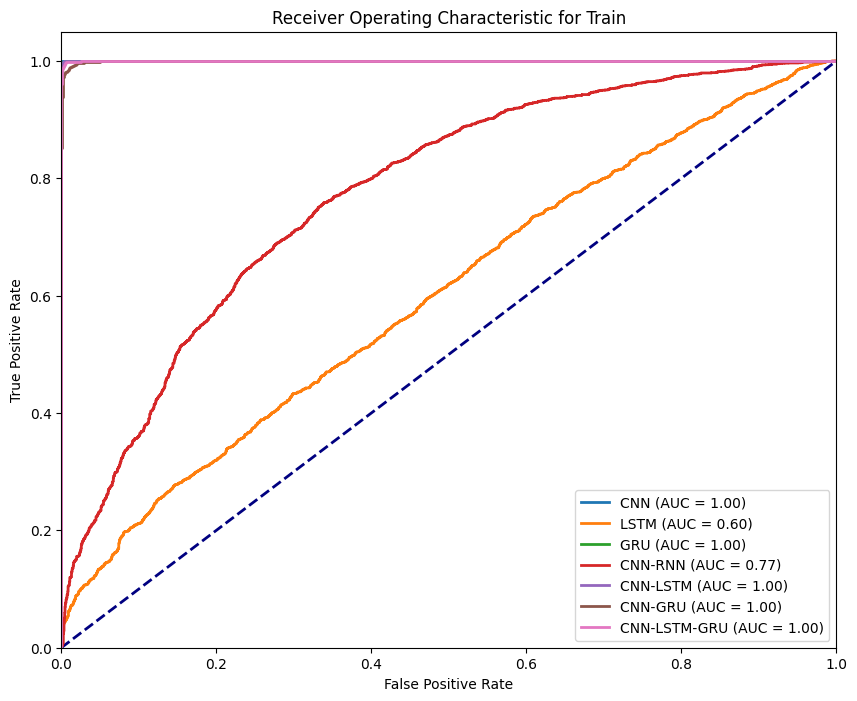

In [18]:
from sklearn.metrics import roc_curve, auc

models = {
    "CNN": CNN,
    "LSTM": LSTM,
    "GRU": GRU,
    "CNN-RNN": CNN_RNN,
    "CNN-LSTM": CNN_LSTM,
    "CNN-GRU": CNN_GRU,
    "CNN-LSTM-GRU": CNN_LSTM_GRU
}

plt.figure(figsize=(10, 8))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

for model_name, model in models.items():
    y_pred_prob = model.predict(X_train_1d).ravel()
    fpr, tpr, thresholds = roc_curve(Y_train, y_pred_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.2f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic for Train')
plt.legend(loc="lower right")
plt.show()

In [19]:
print(roc_auc)

0.9998681306065501


45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 93ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 31s 702ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 21s 473ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 122ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 10s 226ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 143ms/step


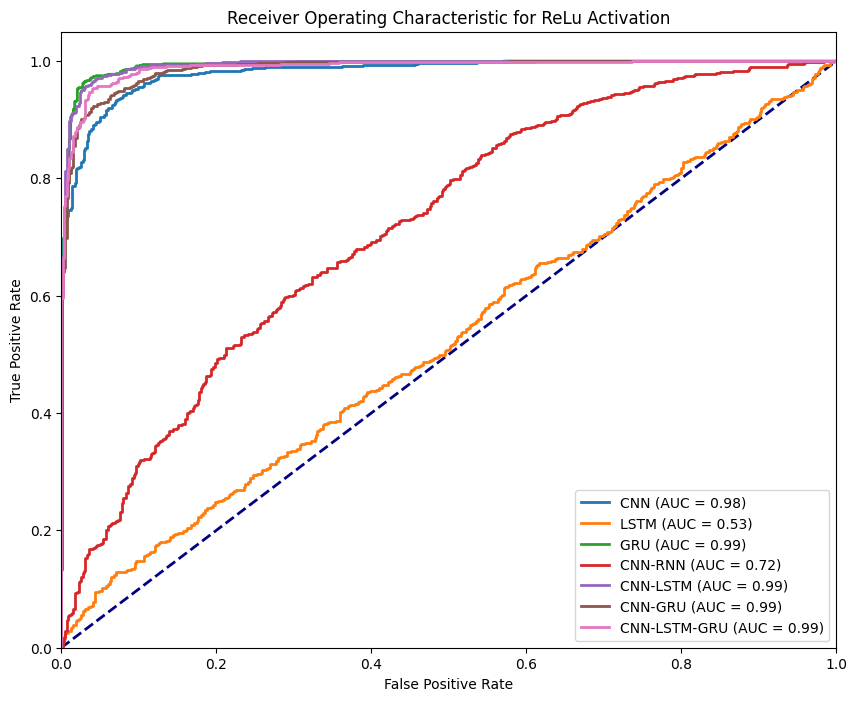

In [20]:
from sklearn.metrics import roc_curve, auc

models = {
    "CNN": CNN,
    "LSTM": LSTM,
    "GRU": GRU,
    "CNN-RNN": CNN_RNN,
    "CNN-LSTM": CNN_LSTM,
    "CNN-GRU": CNN_GRU,
    "CNN-LSTM-GRU": CNN_LSTM_GRU
}

plt.figure(figsize=(10, 8))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

for model_name, model in models.items():
    y_pred_prob = model.predict(X_test_1d).ravel()
    fpr, tpr, thresholds = roc_curve(Y_test, y_pred_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.2f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic for ReLu Activation')
plt.legend(loc="lower right")
plt.show()